In [1]:
!pip install empiricaldist
!pip install pyjanitor
!pip install palmerpenguins
!pip install scipy
!pip install seaborn
!pip install sklearn
!pip install statsmodels
!pip install scikit-learn


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 273.7/273.7 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 665.7/665.7 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 53.1 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py)

In [2]:
import empiricaldist
import janitor
import matplotlib.pyplot as plt
import numpy as np
import palmerpenguins
import pandas as pd
import scipy.stats
import seaborn as sns
import sklearn.metrics
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.stats as ss

import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

In [3]:
%matplotlib inline
sns.set_style(style='whitegrid')
sns.set_context(context='notebook')
plt.rcParams['figure.figsize'] = (11, 9.4)

penguin_color = {
    'Adelie': '#ff6602ff',
    'Gentoo': '#0f7175ff',
    'Chinstrap': '#c65dc9ff'
}

In [4]:
palmerpenguins_pre_df = palmerpenguins.load_penguins()

# **What is the dataType?**

In [5]:
palmerpenguins_pre_df.dtypes

species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object

# **How many variables to each type**

In [6]:
palmerpenguins_pre_df.dtypes.value_counts()

float64    4
str        3
int64      1
Name: count, dtype: int64

# **How many variables and observations (rows) we have?**

In [7]:
palmerpenguins_pre_df.shape

(344, 8)

# **Is there null values?**

In [8]:
from os import rename
(
  palmerpenguins_pre_df.isnull().sum().to_frame()
  .reset_index()
  .assign(has_null=lambda df: df[0] > 0)
  .rename(columns={
      'index': 'variable',
      '0': 'count',
      })
)

,variable,0,has_null
0,species,0,False
1,island,0,False
2,bill_length_mm,2,True
3,bill_depth_mm,2,True
4,flipper_length_mm,2,True
5,body_mass_g,2,True
6,sex,11,True
7,year,0,False


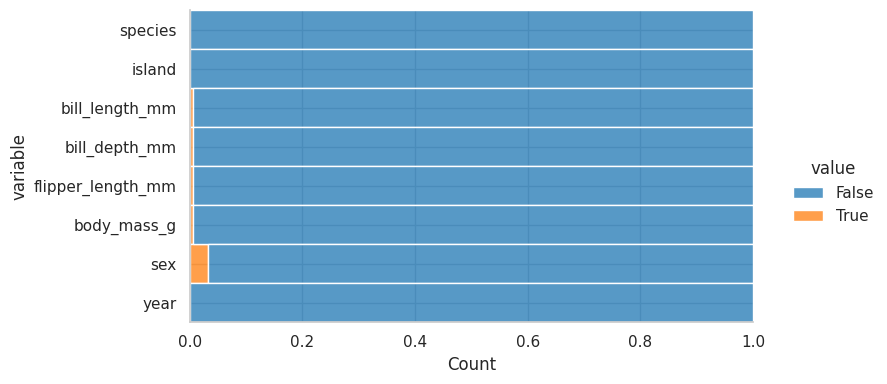

In [9]:
(
    palmerpenguins_pre_df
    .isnull()
    .melt()
    .pipe(
        lambda df: (
            sns.displot(
                data=df,
                y='variable',
                hue='value',
                multiple='fill',
                aspect=2,
                height=4,
            )
        )
    )
)

<Axes: >

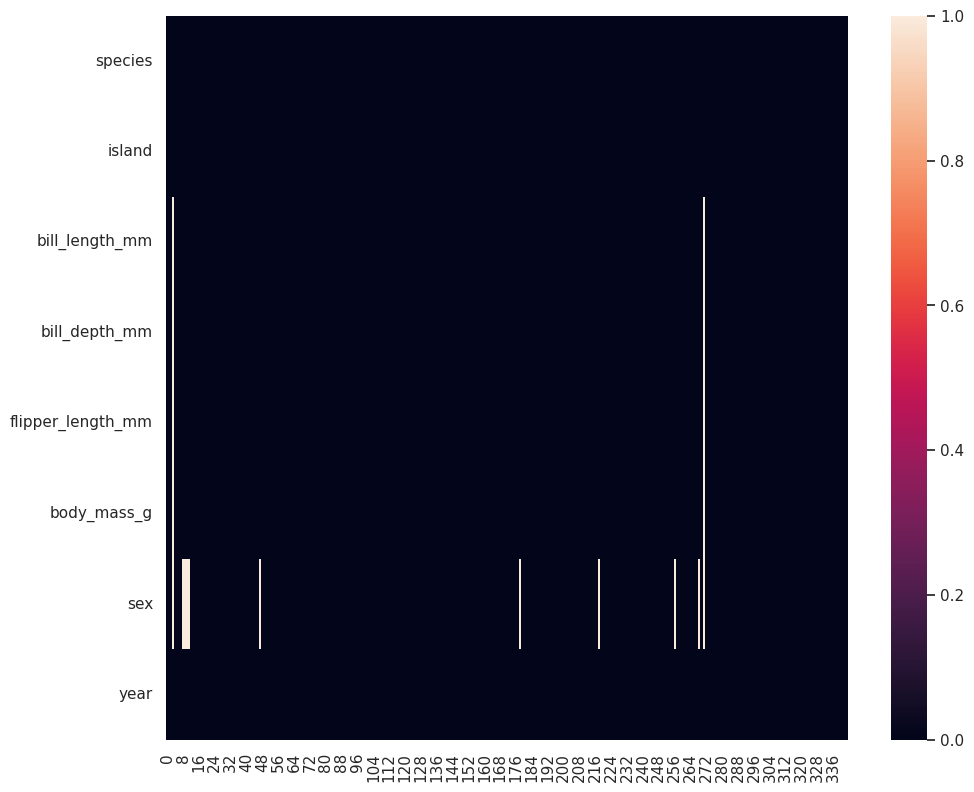

In [10]:
from seaborn.matrix import heatmap
(
    palmerpenguins_pre_df
    .isnull()
    .transpose()
    .pipe(
        lambda df: (
            sns.heatmap(
                data=df
            )
        )
    )
)

# **Drop Null**

In [11]:
#process_penguins_pre_df = (
#    palmerpenguins_pre_df
#    .dropna()
#)

#process_penguins_pre_df

# **Imputed Null**

In [12]:
import numpy as np
import pandas as pd
import sklearn.compose
import sklearn.preprocessing


def custom_encode(df: pd.DataFrame, type_encoder: int):

    df = df.copy()

    category_columns = df.select_dtypes(
        exclude=["number", "bool", "datetime"]
    ).columns.tolist()

    # Convert non-numeric columns to true object dtype and replace pd.NA/strings NaN
    for col in category_columns:
        df[col] = pd.Series(
            df[col].to_numpy(dtype=object, na_value=np.nan),
            index=df.index,
            dtype=object,
        )

    # Cast remaining extension array dtypes (e.g., Int64, Float64) to numpy floats
    for col in df.columns:
        if col not in category_columns and pd.api.types.is_extension_array_dtype(
            df[col]
        ):
            df[col] = df[col].astype(float)

    # OrdinalEncoder needs explicit handling for unknown values or NaNs
    encoder = (
        sklearn.preprocessing.OneHotEncoder(drop="first", sparse_output=False)
        if type_encoder == 1
        else sklearn.preprocessing.OrdinalEncoder(
            handle_unknown="use_encoded_value", unknown_value=-1
        )
    )

    transformer = sklearn.compose.make_column_transformer(
        (encoder, category_columns),
        remainder="passthrough",
        verbose_feature_names_out=False,
    )

    transformer_matrix = transformer.fit_transform(df)

    # Reconstruct the DataFrame
    encoded_df = pd.DataFrame(
        transformer_matrix, columns=transformer.get_feature_names_out()
    )

    return encoded_df, transformer, category_columns


In [13]:
encoded_df, transformer, cat_cols = custom_encode(palmerpenguins_pre_df, type_encoder=0)

# Apply KNN imputation and round the results
knn_imputer = sklearn.impute.KNNImputer()
imputed_matrix = knn_imputer.fit_transform(encoded_df)

processed_palmerpenguins_df = pd.DataFrame(
    imputed_matrix,
    columns=encoded_df.columns,
    index=encoded_df.index
)

X_cat_array = processed_palmerpenguins_df[cat_cols].to_numpy(copy=True)

processed_palmerpenguins_df[cat_cols] = (
    transformer
    .named_transformers_
    .ordinalencoder
    .inverse_transform(X_cat_array)
)

processed_palmerpenguins_df

,species,island,sex,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
0,Adelie,Torgersen,male,39.1,18.70,181.0,3750.0,2007.0
1,Adelie,Torgersen,female,39.5,17.40,186.0,3800.0,2007.0
2,Adelie,Torgersen,female,40.3,18.00,195.0,3250.0,2007.0
3,Adelie,Torgersen,female,38.9,18.24,187.2,3575.0,2007.0
4,Adelie,Torgersen,female,36.7,19.30,193.0,3450.0,2007.0
...,...,...,...,...,...,...,...,...
339,Chinstrap,Dream,male,55.8,19.80,207.0,4000.0,2009.0
340,Chinstrap,Dream,female,43.5,18.10,202.0,3400.0,2009.0
341,Chinstrap,Dream,male,49.6,18.20,193.0,3775.0,2009.0
342,Chinstrap,Dream,male,50.8,19.00,210.0,4100.0,2009.0


<Axes: >

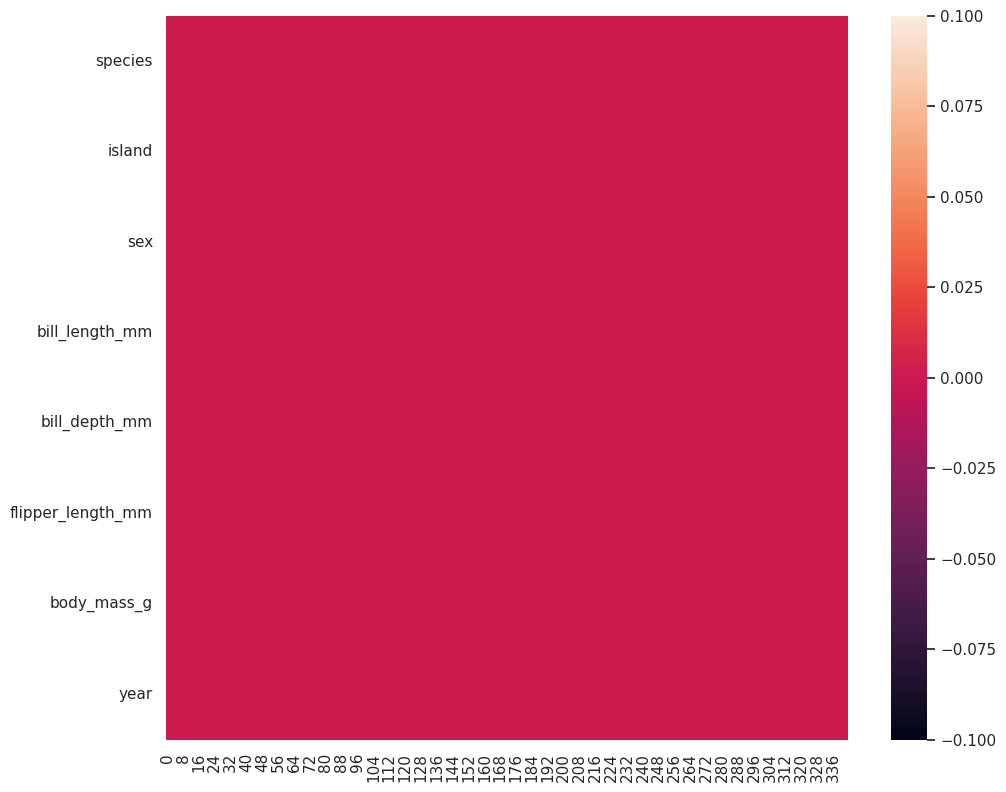

In [14]:
(
    processed_palmerpenguins_df
    .isnull()
    .transpose()
    .pipe(
        lambda df: (
            sns.heatmap(
                data=df
            )
        )
    )
)

In [15]:
processed_palmerpenguins_df.describe(include="all")

,species,island,sex,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,344,344,344,344.000000,344.000000,344.000000,344.000000,344.000000
unique,3,3,2,NaN,NaN,NaN,NaN,NaN
top,Adelie,Biscoe,female,NaN,NaN,NaN,NaN,NaN
freq,152,168,174,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,43.918372,17.149012,200.928488,4202.645349,2008.029070
std,NaN,NaN,NaN,5.454248,1.972383,14.074864,801.913151,0.818356
min,NaN,NaN,NaN,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,NaN,NaN,NaN,39.200000,15.575000,190.000000,3550.000000,2007.000000
50%,NaN,NaN,NaN,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,NaN,NaN,NaN,48.500000,18.700000,213.250000,4756.250000,2009.000000


In [16]:
processed_palmerpenguins_df = processed_palmerpenguins_df.astype({
    'species': 'category',
    'island': 'category',
    'sex': 'category',
    }
)

In [17]:
processed_palmerpenguins_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   species            344 non-null    category
 1   island             344 non-null    category
 2   sex                344 non-null    category
 3   bill_length_mm     344 non-null    float64 
 4   bill_depth_mm      344 non-null    float64 
 5   flipper_length_mm  344 non-null    float64 
 6   body_mass_g        344 non-null    float64 
 7   year               344 non-null    float64 
dtypes: category(3), float64(5)
memory usage: 14.7 KB


<Axes: title={'center': 'Penguin species'}, xlabel='species'>

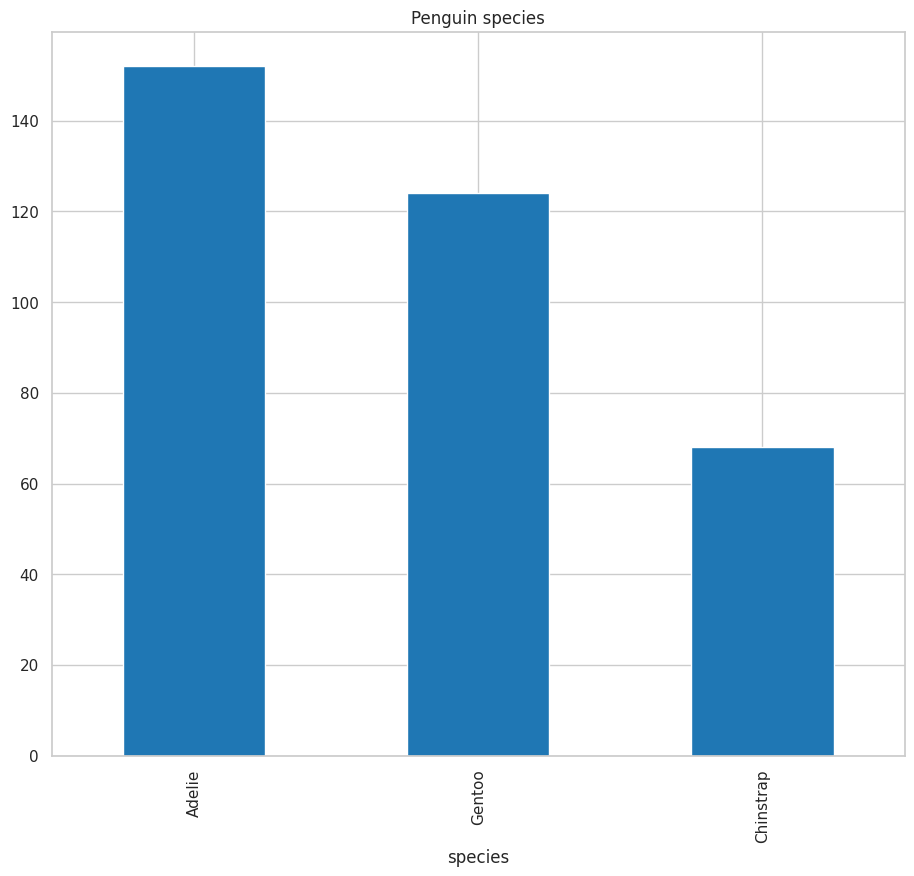

In [18]:
(
    processed_palmerpenguins_df['species']
    .value_counts()
    .plot(
        kind='bar',
        title='Penguin species'
    )
)

/tmp/ipykernel_1864/1403447422.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


<Axes: xlabel='species', ylabel='count'>

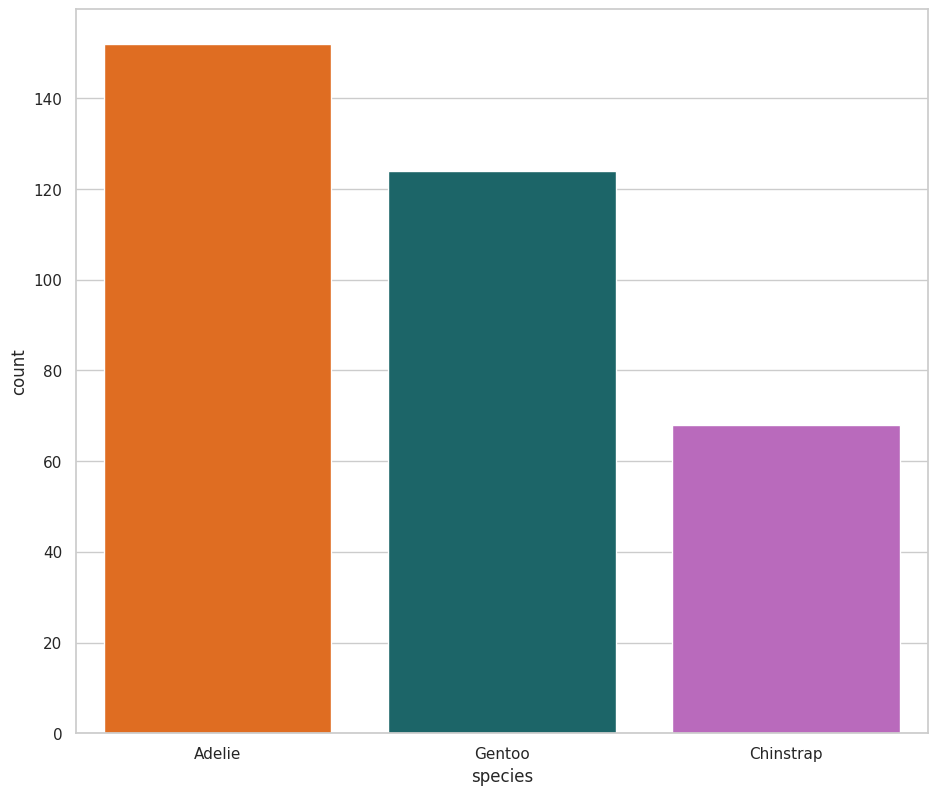

In [19]:
(
    processed_palmerpenguins_df['species']
    .value_counts()
    .reset_index()
    .pipe(
        lambda df: (
            sns.barplot(
                data=df,
                x='species',
                y='count',
                palette=penguin_color,
                order=df.sort_values('count',ascending=False)['species']
                )
            )
        )
    )


# **Proportions**

/usr/local/lib/python3.13/dist-packages/pandas_flavor/register.py:161: FutureWarning: This function will be deprecated in a 1.x release. Please use `pd.DataFrame.assign` instead.
  return method(self._obj, *args, **kwargs)


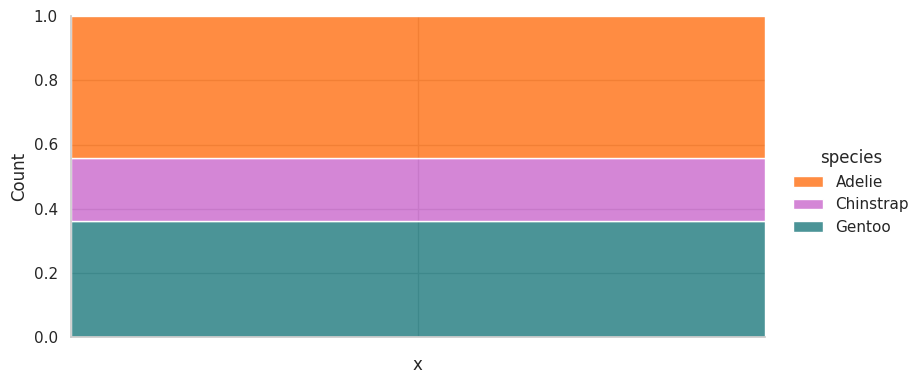

In [20]:
(
    processed_palmerpenguins_df
    .add_column('x','')
    .pipe(
        lambda df: (
            sns.displot(
                data=df,
                x='x',
                hue='species',
                multiple='fill',
                aspect=2,
                height=4,
                palette=penguin_color,
            )
        )
    )
)

# **Central Tendency Measures**

In [21]:
processed_palmerpenguins_df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,344.000000,344.000000,344.000000,344.000000,344.000000
mean,43.918372,17.149012,200.928488,4202.645349,2008.029070
std,5.454248,1.972383,14.074864,801.913151,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.200000,15.575000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.250000,4756.250000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


In [22]:
processed_palmerpenguins_df.mode()

,species,island,sex,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
0,Adelie,Biscoe,female,41.1,17.0,190.0,3800.0,2009.0


# **Dispersion Measure**

In [23]:
dispertion_measures_df = (pd.DataFrame(
    index=processed_palmerpenguins_df.select_dtypes(include='number').columns
    )
    .assign(
        mean=processed_palmerpenguins_df.mean(numeric_only=True),
        median=processed_palmerpenguins_df.median(numeric_only=True),
        range=processed_palmerpenguins_df.max(numeric_only=True) - processed_palmerpenguins_df.min(numeric_only=True),
        IQR=processed_palmerpenguins_df.quantile(0.75) - processed_palmerpenguins_df.quantile(0.25),
        Q1=processed_palmerpenguins_df.quantile(0.25),
        Q3=processed_palmerpenguins_df.quantile(0.75),
        std=processed_palmerpenguins_df.std(numeric_only=True),
        variance=processed_palmerpenguins_df.var(numeric_only=True),
        skewness=processed_palmerpenguins_df.skew(numeric_only=True)
        )
)

dispertion_measures_df

,mean,median,range,IQR,Q1,Q3,std,variance,skewness
bill_length_mm,43.918372,44.45,27.5,9.300,39.200,48.50,5.454248,29.748823,0.053631
bill_depth_mm,17.149012,17.30,8.4,3.125,15.575,18.70,1.972383,3.890296,-0.141698
flipper_length_mm,200.928488,197.00,59.0,23.250,190.000,213.25,14.074864,198.101810,0.343560
body_mass_g,4202.645349,4050.00,3600.0,1206.250,3550.000,4756.25,801.913151,643064.701844,0.467513
year,2008.029070,2008.00,2.0,2.000,2007.000,2009.00,0.818356,0.669706,-0.053728


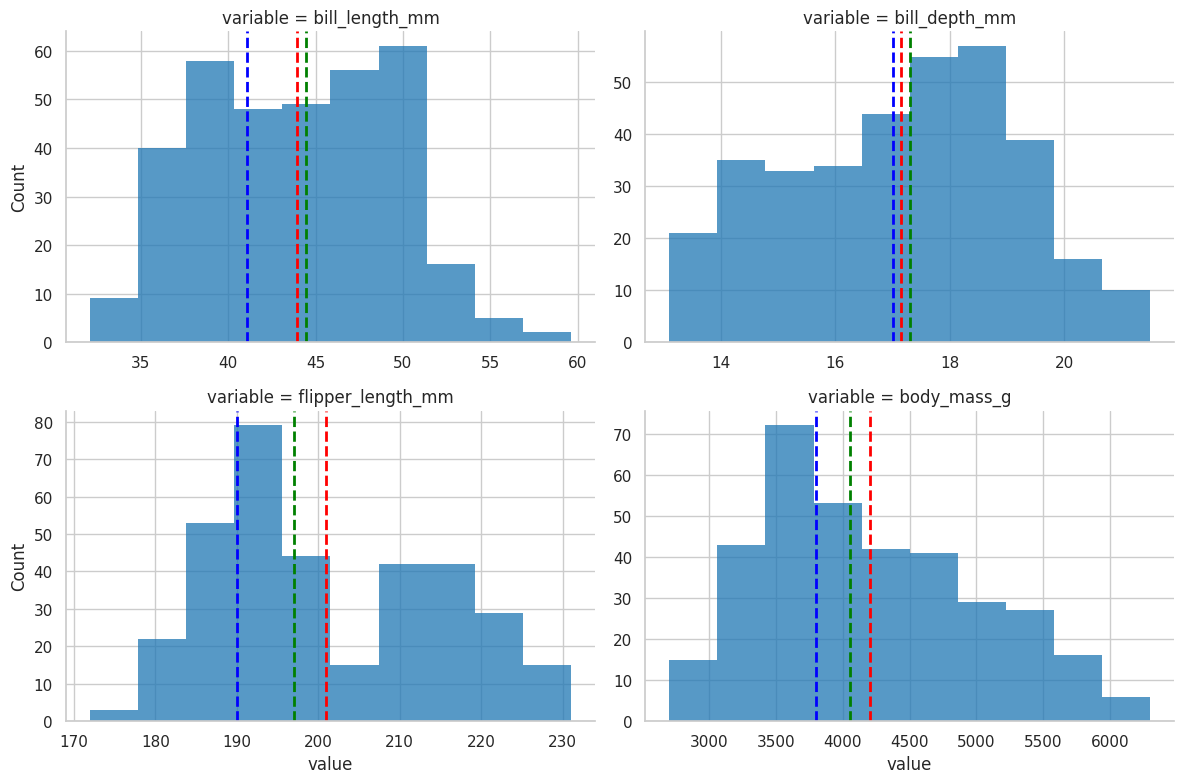

In [24]:
import matplotlib.pyplot as plt
import pandas as pd

def draw_central_tendency_measures(
    data: pd.DataFrame,
    x_value: str = 'value',
    include_mode: bool = True,
    round_decimals: int = None,
    **kwargs
):

    # 1. Cálculos estables (Media y Mediana)
    mean_val = data[x_value].mean()
    median_val = data[x_value].median()

    plt.axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Media: {mean_val:.1f}')
    plt.axvline(median_val, color='green', linestyle='--', linewidth=2, label=f'Mediana: {median_val:.1f}')

    # 2. Control e inclusión de la Moda
    if include_mode:
        # Si es una variable continua con muchos decimales, aplicamos un redondeo temporal
        series_for_mode = data[x_value].round(round_decimals) if round_decimals is not None else data[x_value]

        mode_series = series_for_mode.mode()
        if not mode_series.empty:
            mode_val = mode_series.iloc[0]
            plt.axvline(mode_val, color='blue', linestyle='--', linewidth=2, label=f'Moda: {mode_val:.1f}')



(
    processed_palmerpenguins_df
    .pipe(lambda df:
        sns.displot(
            data=df.melt(value_vars=['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']),
            x="value",
            col="variable",
            kind="hist",
            common_bins=False,
            bins=10,
            facet_kws=dict(sharex=False, sharey=False),
            col_wrap=2,
            height=4,
            aspect=1.5
        )
    ).map_dataframe(draw_central_tendency_measures)
)


# **BoxPlot**

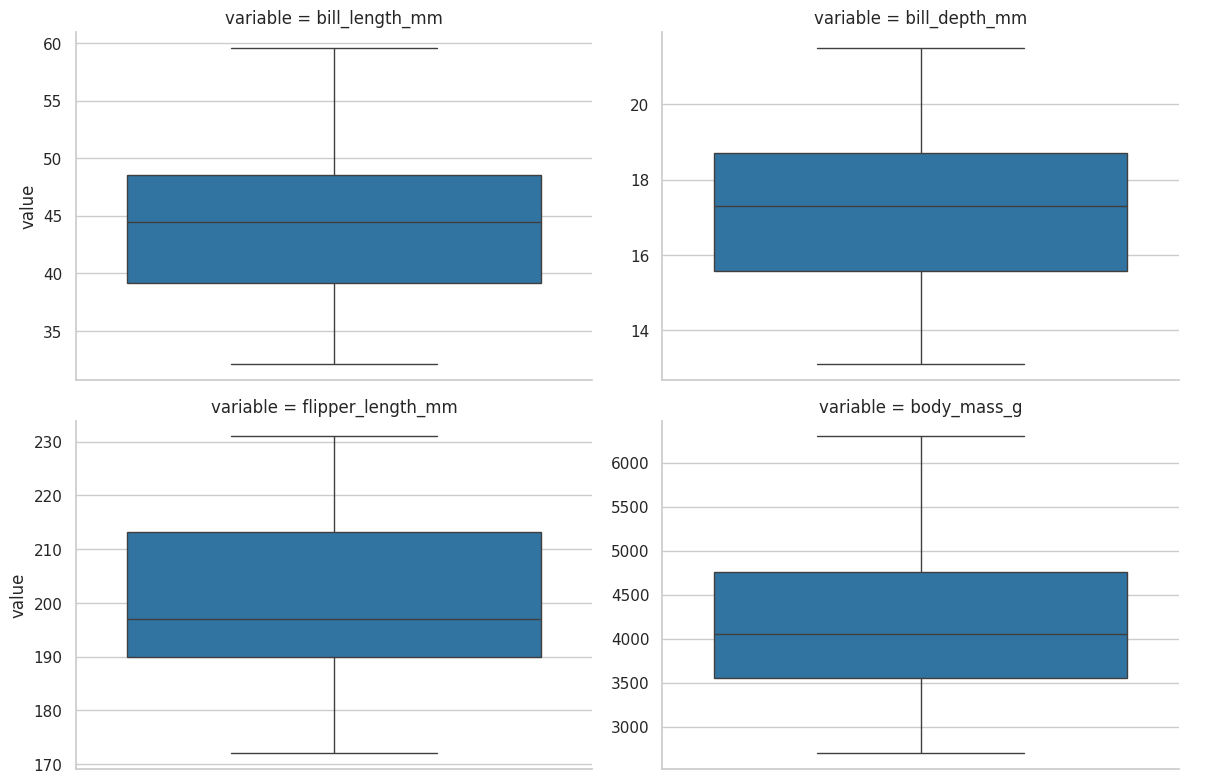

In [25]:
(
    processed_palmerpenguins_df
    .pipe(lambda df:
        sns.catplot(
            data=df.melt(value_vars=['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']),
            y="value",
            col="variable",
            kind="box",
            sharey=False,
            col_wrap=2,
            height=4,
            aspect=1.5
        )
    )
)


# **STATICS PRDECTIVE**

<Axes: xlabel='flipper_length_mm', ylabel='Probability'>

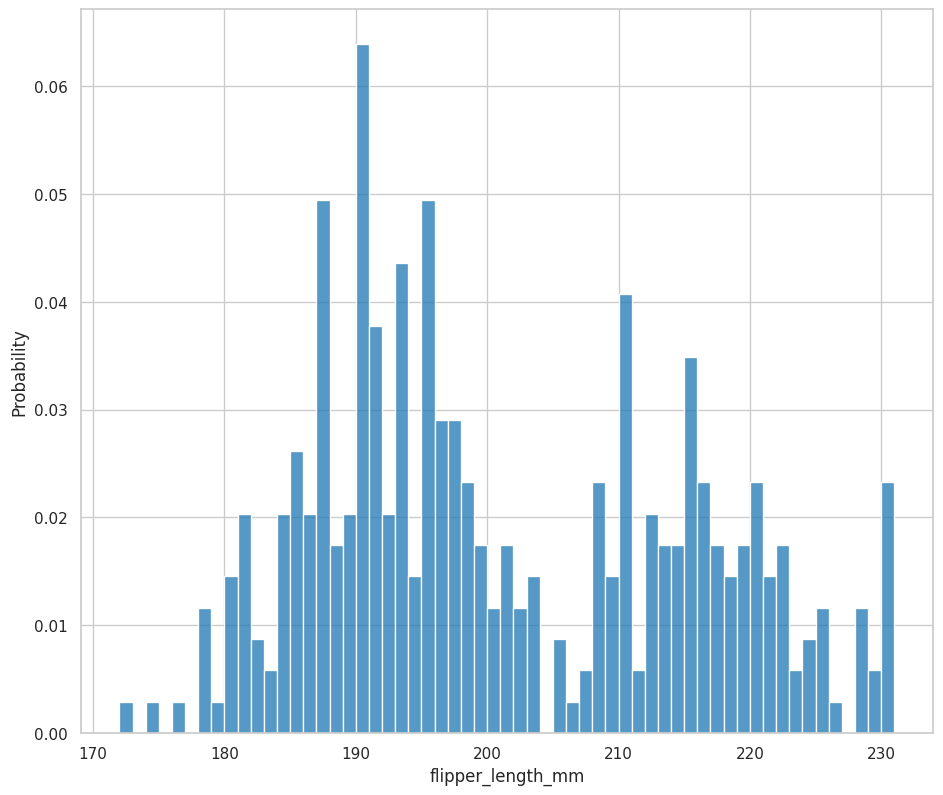

In [26]:
sns.histplot(
    data=processed_palmerpenguins_df,
    x='flipper_length_mm',
    binwidth=1,
    stat='probability'
)

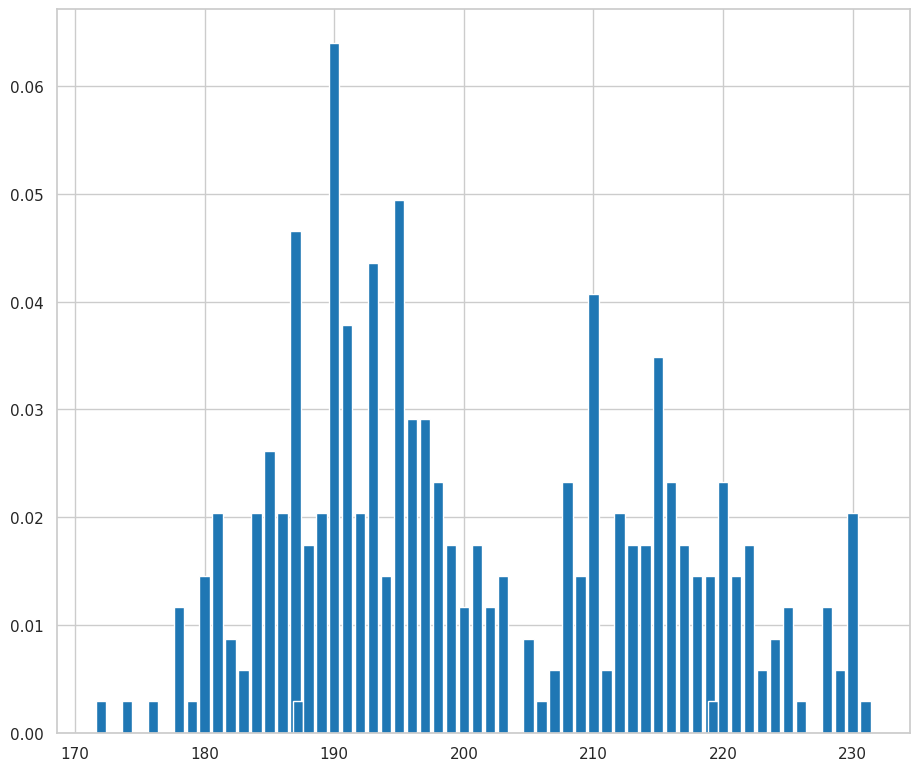

In [27]:
pmf_flipper_length_mm = empiricaldist.Pmf.from_seq(
    processed_palmerpenguins_df['flipper_length_mm'],
    normalize=True,
)

pmf_flipper_length_mm.bar()



In [28]:
pmf_flipper_length_mm(190)

np.float64(0.06395348837209303)

<Axes: xlabel='flipper_length_mm', ylabel='Proportion'>

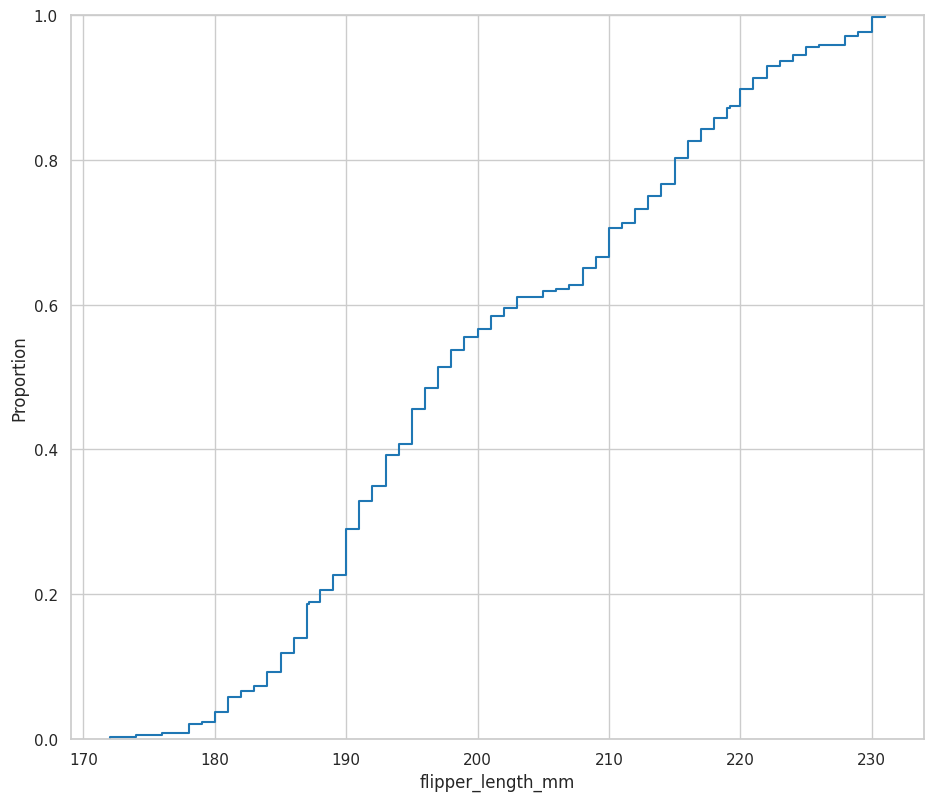

In [29]:
sns.ecdfplot(
    data=processed_palmerpenguins_df,
    x='flipper_length_mm',
)

<Axes: xlabel='flipper_length_mm'>

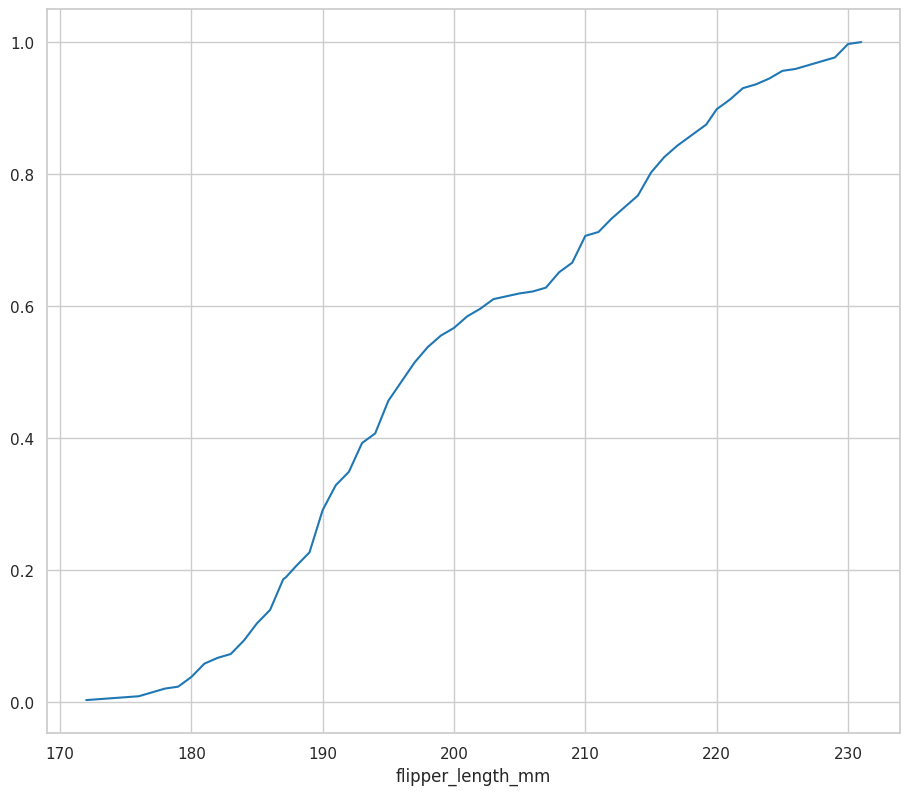

In [30]:
cdf_flipper_length_mm = empiricaldist.Cdf.from_seq(
    processed_palmerpenguins_df['flipper_length_mm'],
    normalize=True,
)

cdf_flipper_length_mm.plot()


In [31]:
cdf_flipper_length_mm(230)

array(0.99709302)

<Axes: xlabel='flipper_length_mm', ylabel='Proportion'>

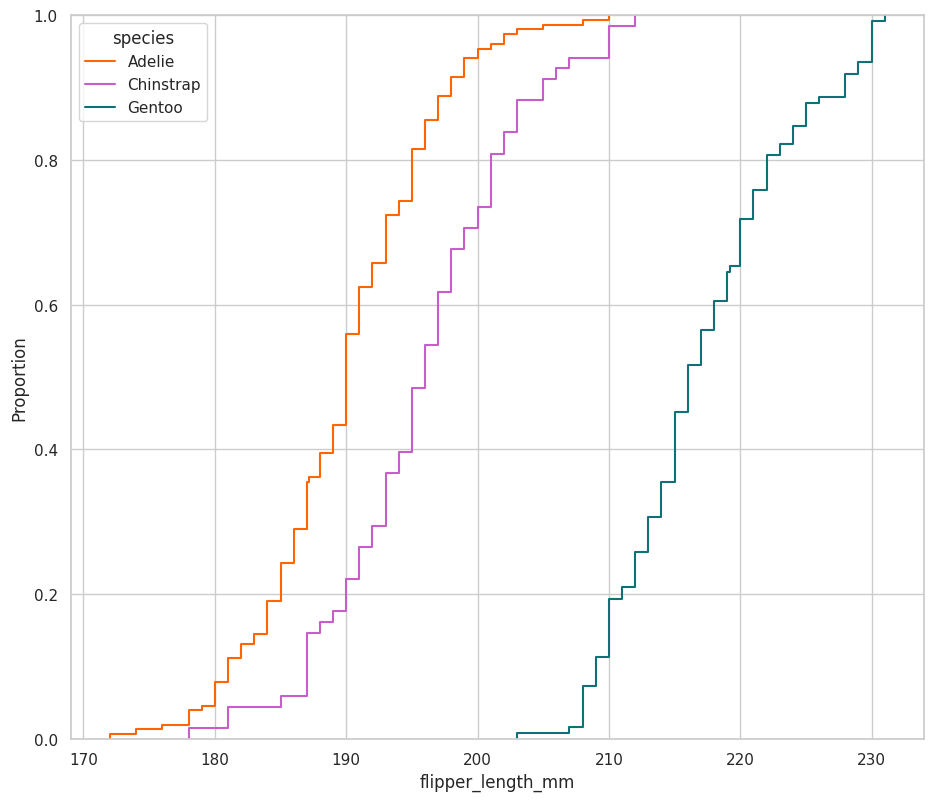

In [32]:
sns.ecdfplot(
    data=processed_palmerpenguins_df,
    x='flipper_length_mm',
    hue='species',
    palette=penguin_color,
)


# **DENSITY PROBABILITY FUNCTIONS**

<Axes: xlabel='flipper_length_mm', ylabel='Density'>

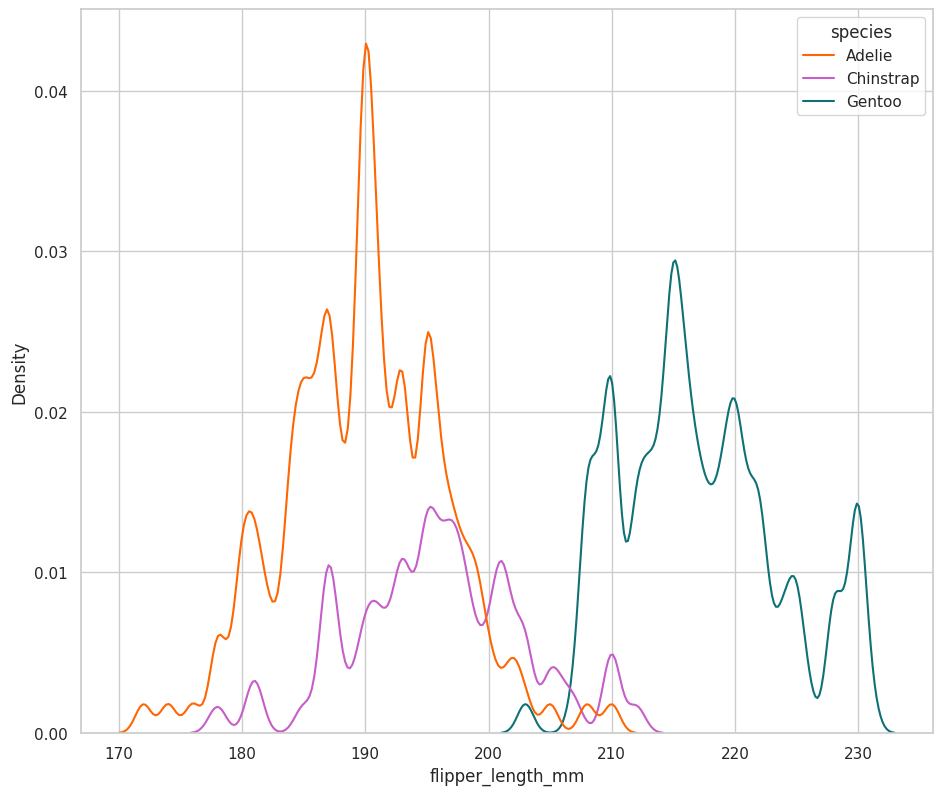

In [33]:
sns.kdeplot(
    data=processed_palmerpenguins_df,
    x='flipper_length_mm',
    bw_method=0.1,
    hue='species',
    palette=penguin_color,
)

In [34]:
stats = processed_palmerpenguins_df.body_mass_g.describe()
stats

count     344.000000
mean     4202.645349
std       801.913151
min      2700.000000
25%      3550.000000
50%      4050.000000
75%      4756.250000
max      6300.000000
Name: body_mass_g, dtype: float64

<Axes: xlabel='body_mass_g'>

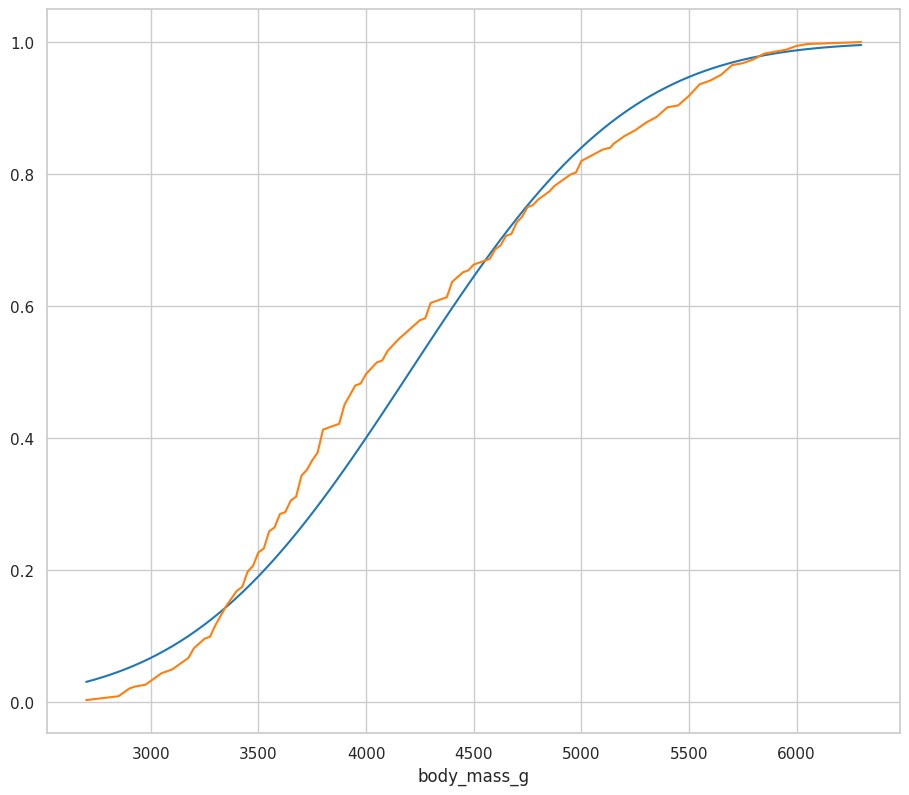

In [35]:
xs = np.linspace(stats['min'], stats['max'], 100)
ys = scipy.stats.norm(stats['mean'], stats['std']).cdf(xs)

plt.plot(xs, ys)

empiricaldist.Cdf.from_seq(
    processed_palmerpenguins_df['body_mass_g'],
    normalize=True
).plot()

<Axes: xlabel='body_mass_g', ylabel='Density'>

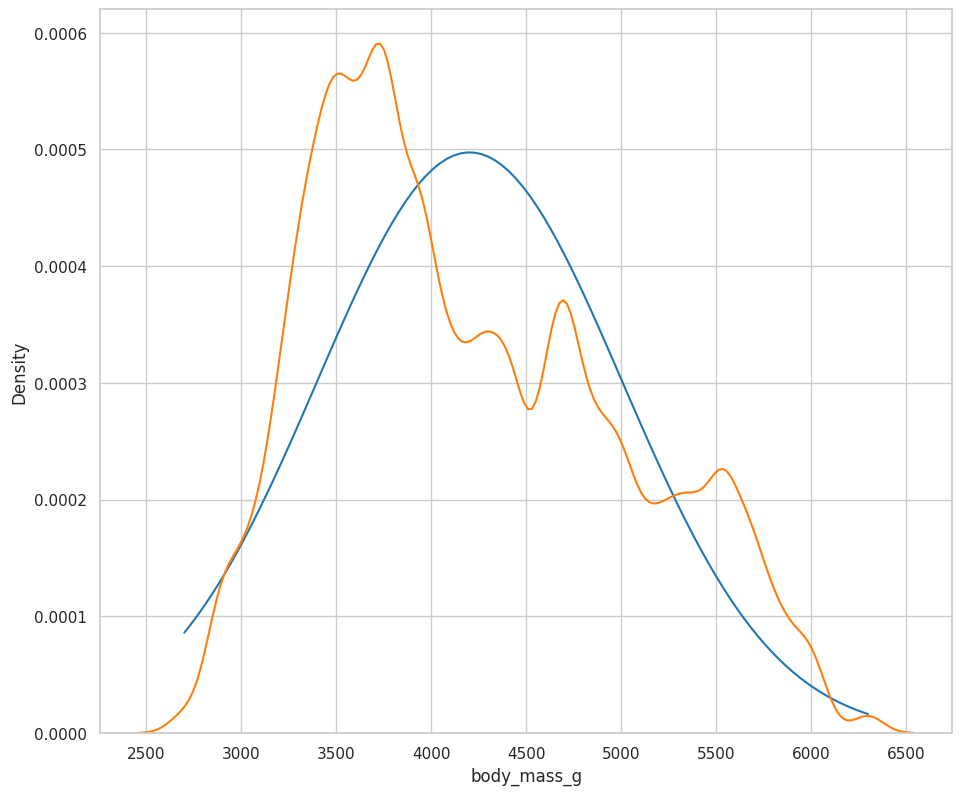

In [36]:
xs = np.linspace(stats['min'], stats['max'], 100)
ys = scipy.stats.norm(stats['mean'], stats['std']).pdf(xs)

plt.plot(xs, ys)

sns.kdeplot(
    data=processed_palmerpenguins_df,
    x='body_mass_g',
    bw_method=0.1,
)

# **Big numbers law**

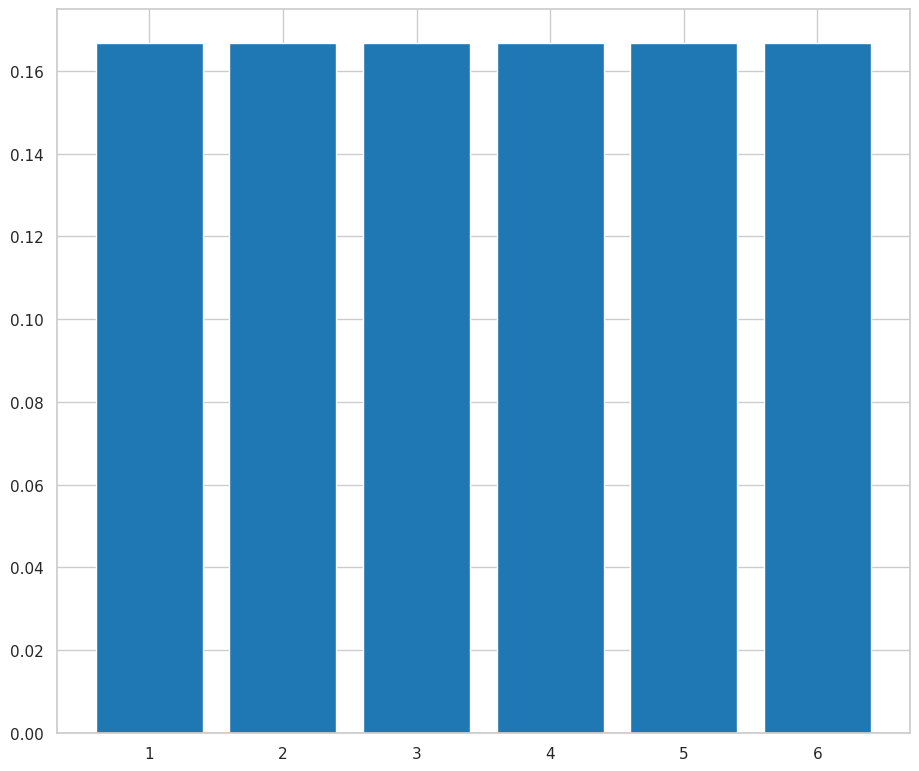

In [37]:
dice = empiricaldist.Pmf.from_seq([1, 2, 3, 4, 5, 6])
dice.bar()

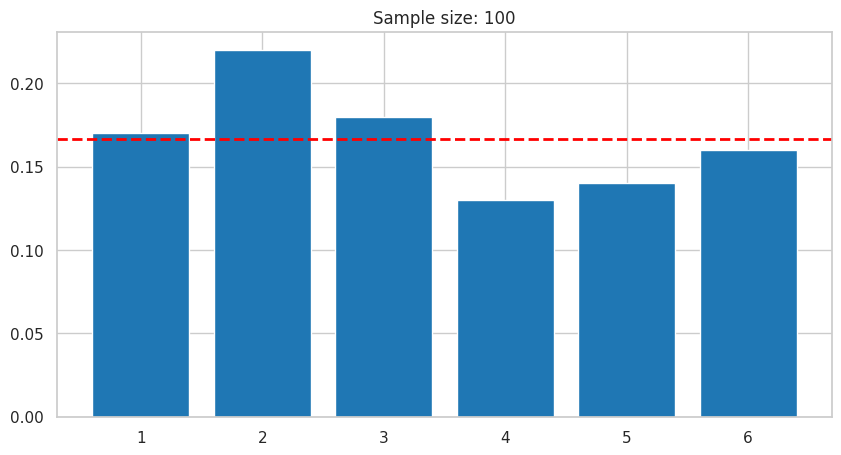

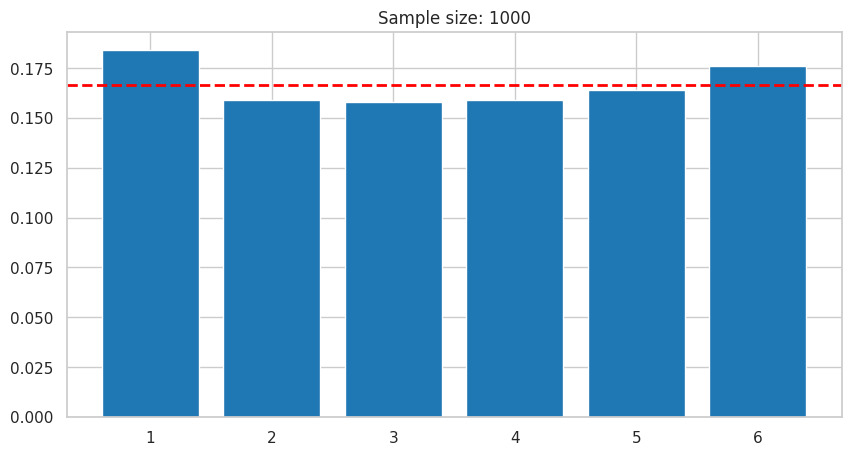

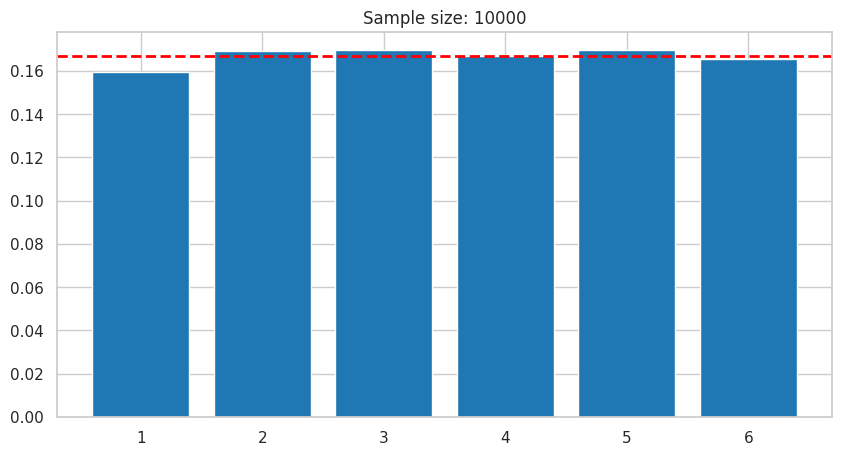

In [38]:
for sample_size in (1e2, 1e3, 1e4):
  sample_size = int(sample_size)
  values = dice.sample(sample_size)
  sample_pmf = empiricaldist.Pmf.from_seq(values)

  plt.figure(figsize=(10,5))
  sample_pmf.bar()
  plt.title(f'Sample size: {sample_size}')
  plt.axhline(y=1/6, color='red', linestyle='--', linewidth=2)

# **LIMIT CENTRAL TEOREM**

<Axes: xlabel='sex'>

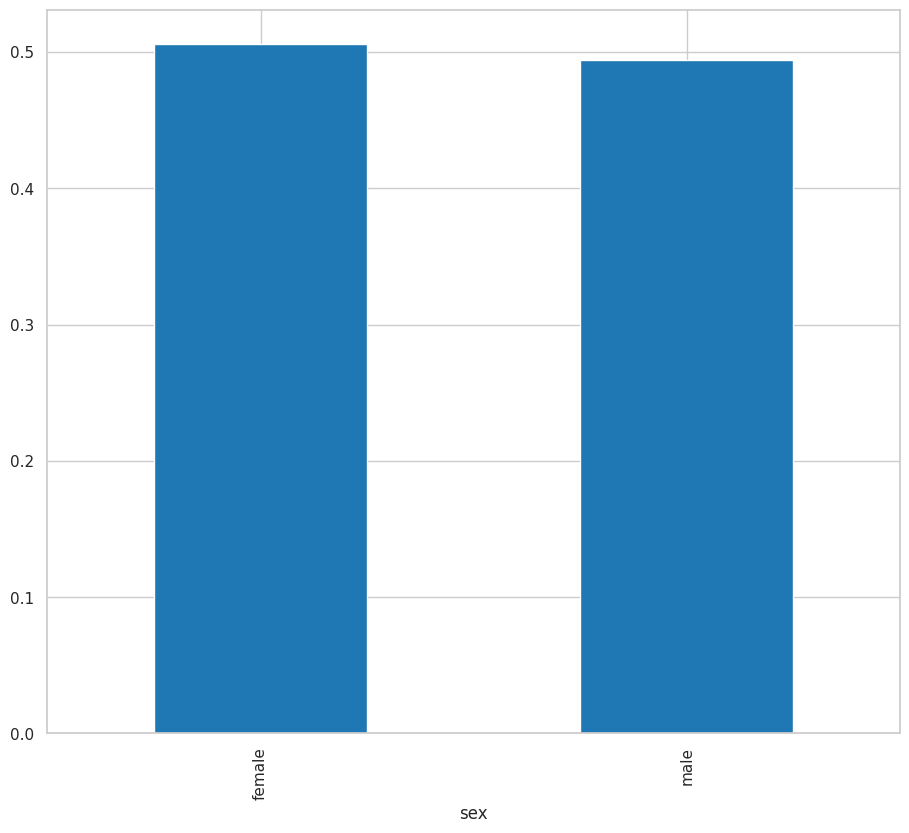

In [39]:
processed_palmerpenguins_df['sex'].value_counts(normalize=True).plot(kind='bar')

In [40]:
sex_numeric = processed_palmerpenguins_df['sex'].astype(str).replace(
    ['male', 'female'],
    [1, 0]
)

number_samples = 1000
sample_size = 20

samples_dict = {
    f"sample_{i}": sex_numeric.sample(sample_size, replace=True).to_numpy()
    for i in range(1, number_samples + 1)
}

samples_df = pd.DataFrame(samples_dict)
samples_df.mean()

sample_1        0.4
sample_2       0.45
sample_3        0.4
sample_4        0.6
sample_5        0.4
               ... 
sample_996      0.3
sample_997     0.55
sample_998      0.6
sample_999     0.75
sample_1000     0.7
Length: 1000, dtype: object

# **Scatter PLot**

<Axes: xlabel='bill_length_mm', ylabel='bill_depth_mm'>

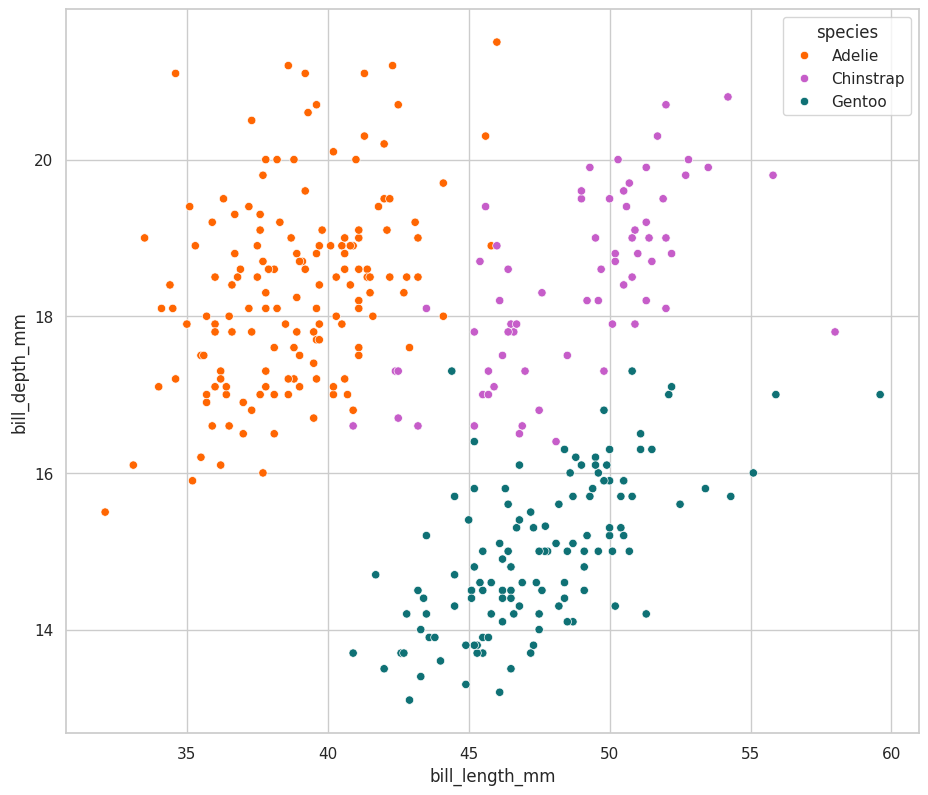

In [41]:
sns.scatterplot(
    data=processed_palmerpenguins_df,
    x='bill_length_mm',
    y='bill_depth_mm',
    hue='species',
    palette=penguin_color,
)

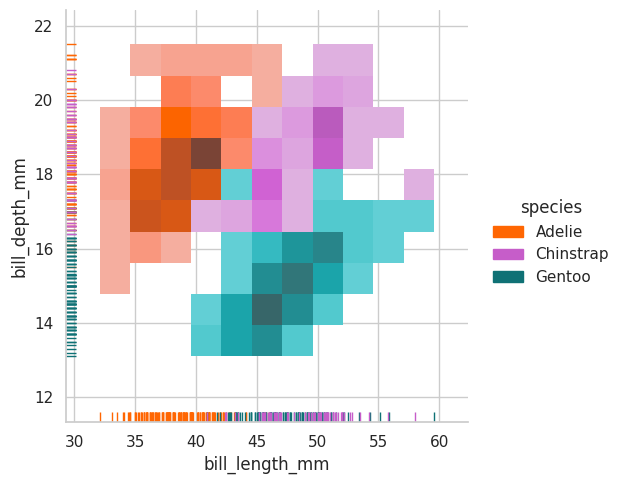

In [42]:
sns.displot(
    data=processed_palmerpenguins_df,
    x='bill_length_mm',
    y='bill_depth_mm',
    rug=True,
    hue='species',
    palette=penguin_color,
)

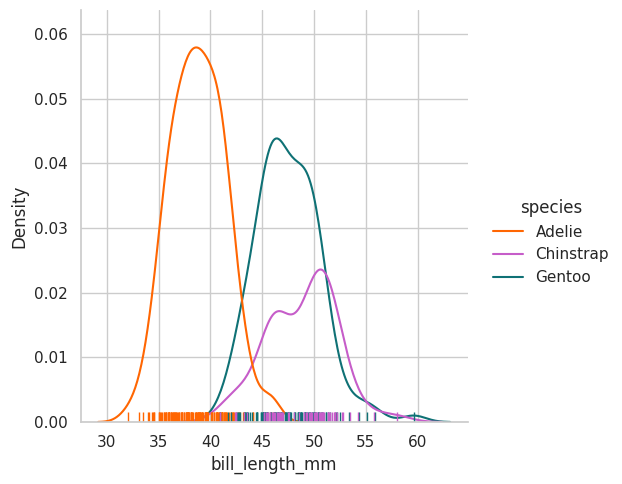

In [43]:
sns.displot(
    data=processed_palmerpenguins_df,
    x='bill_length_mm',
    rug=True,
    kind='kde',
    hue='species',
    palette=penguin_color,
)

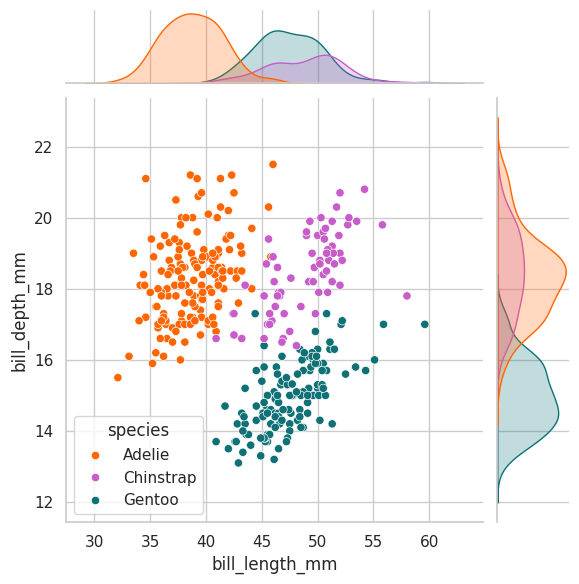

In [44]:
sns.jointplot(
    data=processed_palmerpenguins_df,
    x='bill_length_mm',
    y='bill_depth_mm',
    hue='species',
    palette=penguin_color,
)

<Axes: xlabel='species', ylabel='flipper_length_mm'>

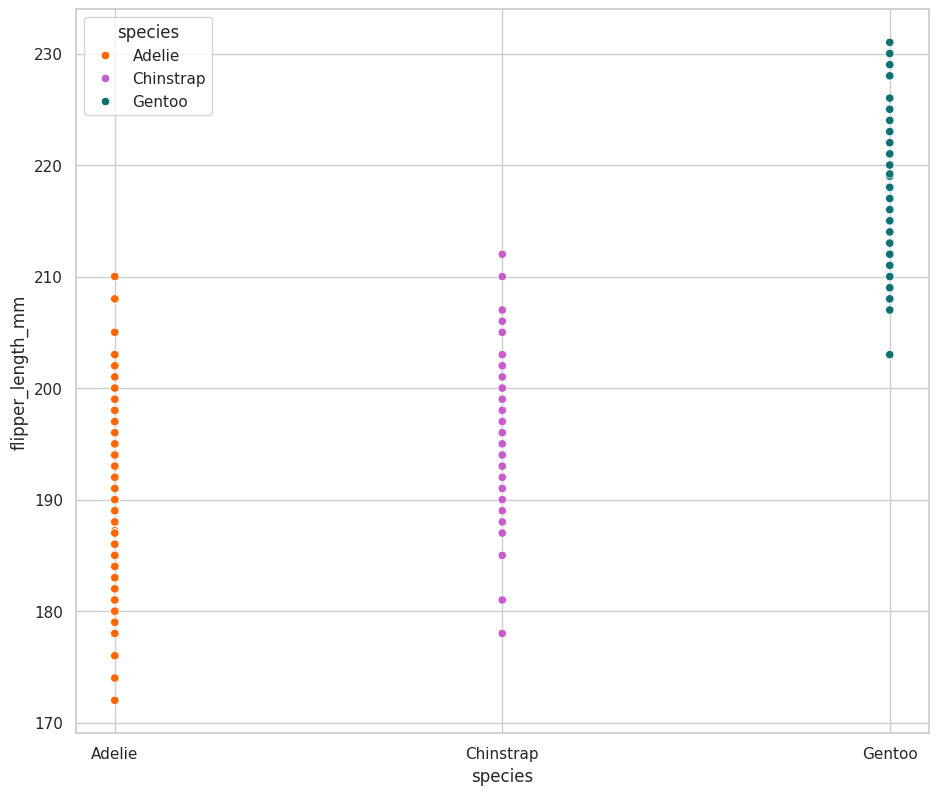

In [45]:
sns.scatterplot(
    data=processed_palmerpenguins_df,
    x='species',
    y='flipper_length_mm',
    hue='species',
    palette=penguin_color,
)

<Axes: xlabel='species', ylabel='flipper_length_mm'>

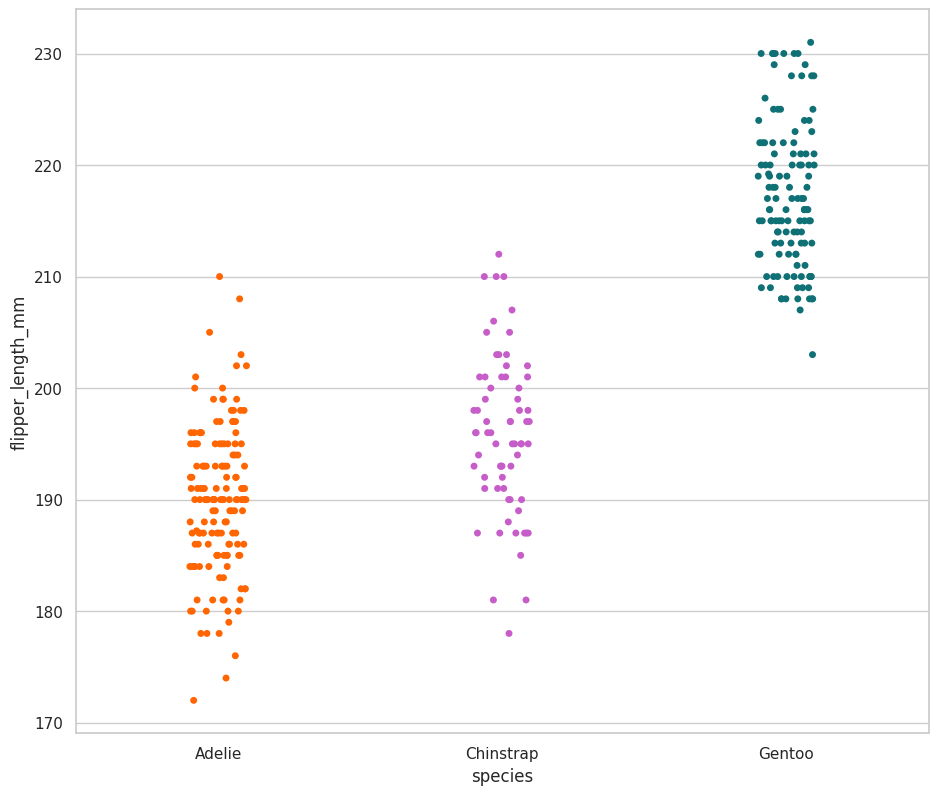

In [46]:
sns.stripplot(
    data=processed_palmerpenguins_df,
    x='species',
    y='flipper_length_mm',
    hue='species',
    palette=penguin_color,
)

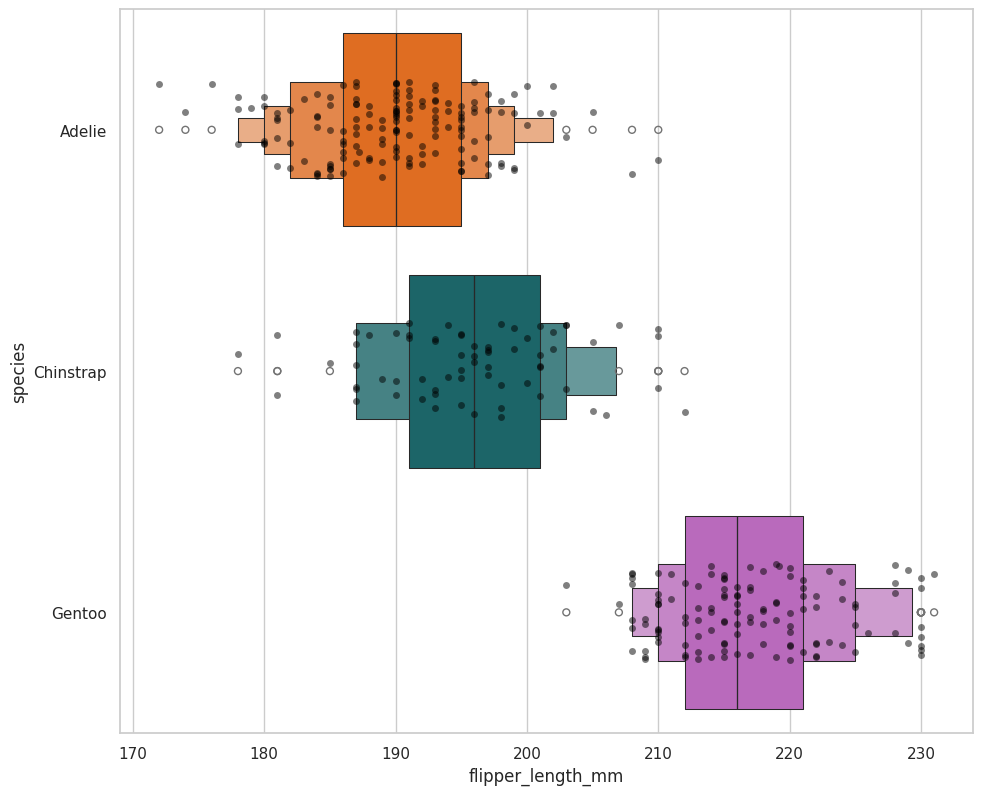

In [47]:


orden_especies = ['Adelie', 'Chinstrap', 'Gentoo']


ax = sns.boxenplot(
    data=processed_palmerpenguins_df,
    y='species',
    x='flipper_length_mm',
    hue='species',
    palette=penguin_color,
    order=orden_especies,
    dodge=False,          # <--- Centra las cajas en la línea de la categoría
    legend=False
)


ax = sns.stripplot(
    data=processed_palmerpenguins_df,
    y='species',
    x='flipper_length_mm',
    color='black',
    order=orden_especies,
    alpha=0.5,            # Hace los puntos ligeramente transparentes
    jitter=0.2            # Controla la dispersión vertical de los puntos
)


<Axes: xlabel='species', ylabel='flipper_length_mm'>

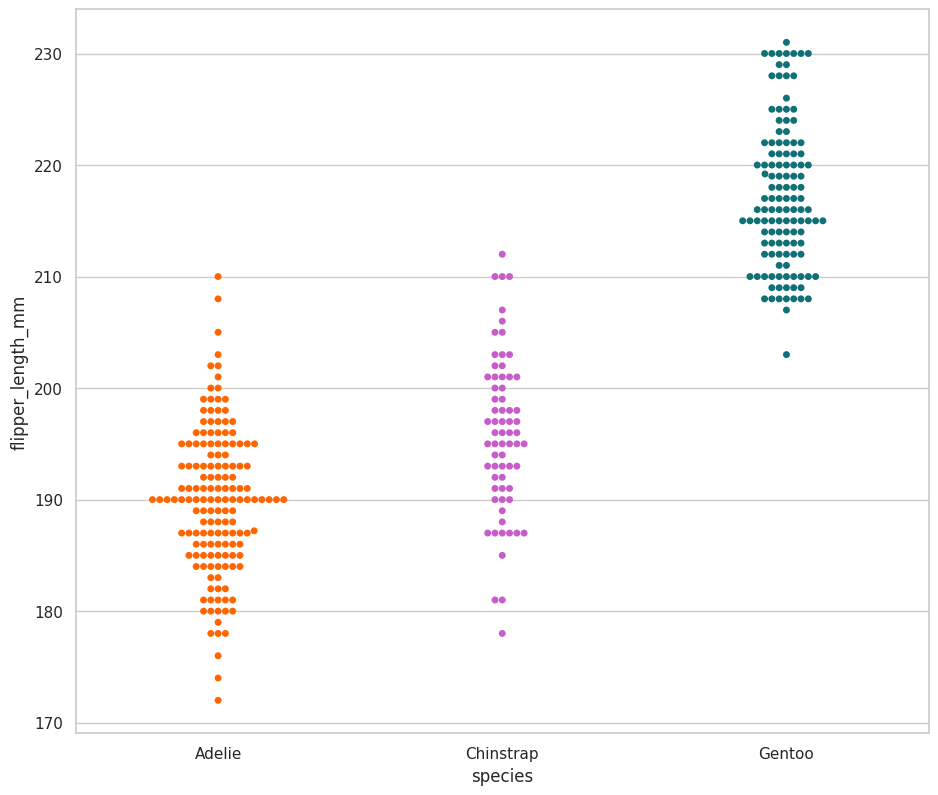

In [48]:
sns.swarmplot(
    data=processed_palmerpenguins_df,
    x='species',
    y='flipper_length_mm',
    hue='species',
    palette=penguin_color,
)

# **CORRELATION**

In [49]:
processed_palmerpenguins_df.corr(numeric_only=True)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
bill_length_mm,1.000000,-0.237564,0.657637,0.596711,0.059985
bill_depth_mm,-0.237564,1.000000,-0.585697,-0.474168,-0.065223
flipper_length_mm,0.657637,-0.585697,1.000000,0.871984,0.176350
body_mass_g,0.596711,-0.474168,0.871984,1.000000,0.048795
year,0.059985,-0.065223,0.176350,0.048795,1.000000


<Axes: >

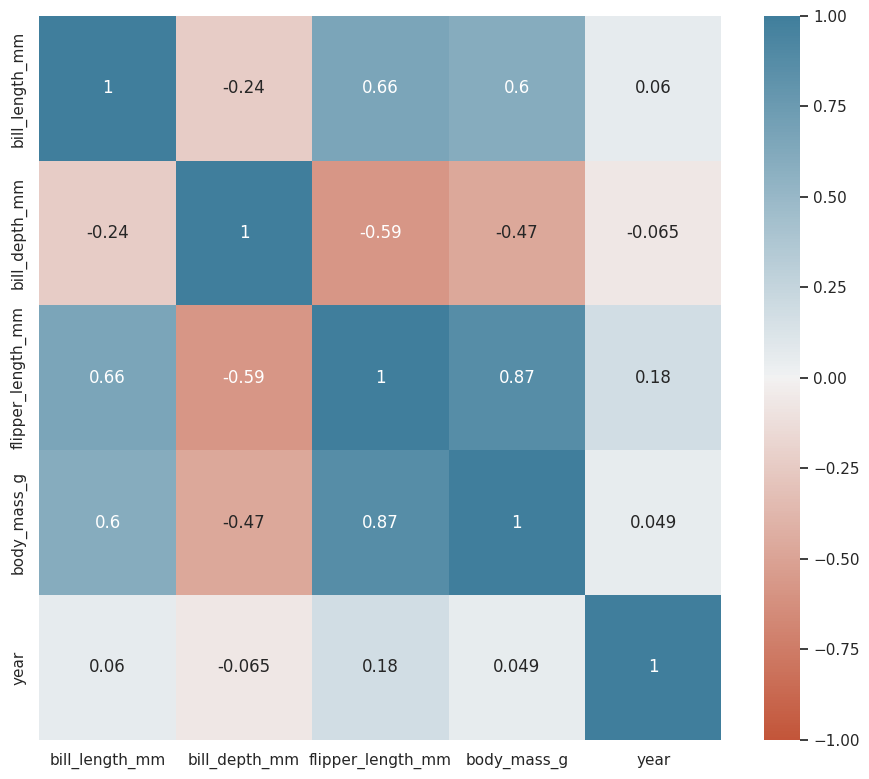

In [50]:
processed_palmerpenguins_df.corr(numeric_only=True)
sns.heatmap(
    data=processed_palmerpenguins_df.corr(numeric_only=True),
    center=0,
    cmap=sns.diverging_palette(20, 230, as_cmap=True),
    vmin=-1,
    vmax=1,
    annot=True,
)

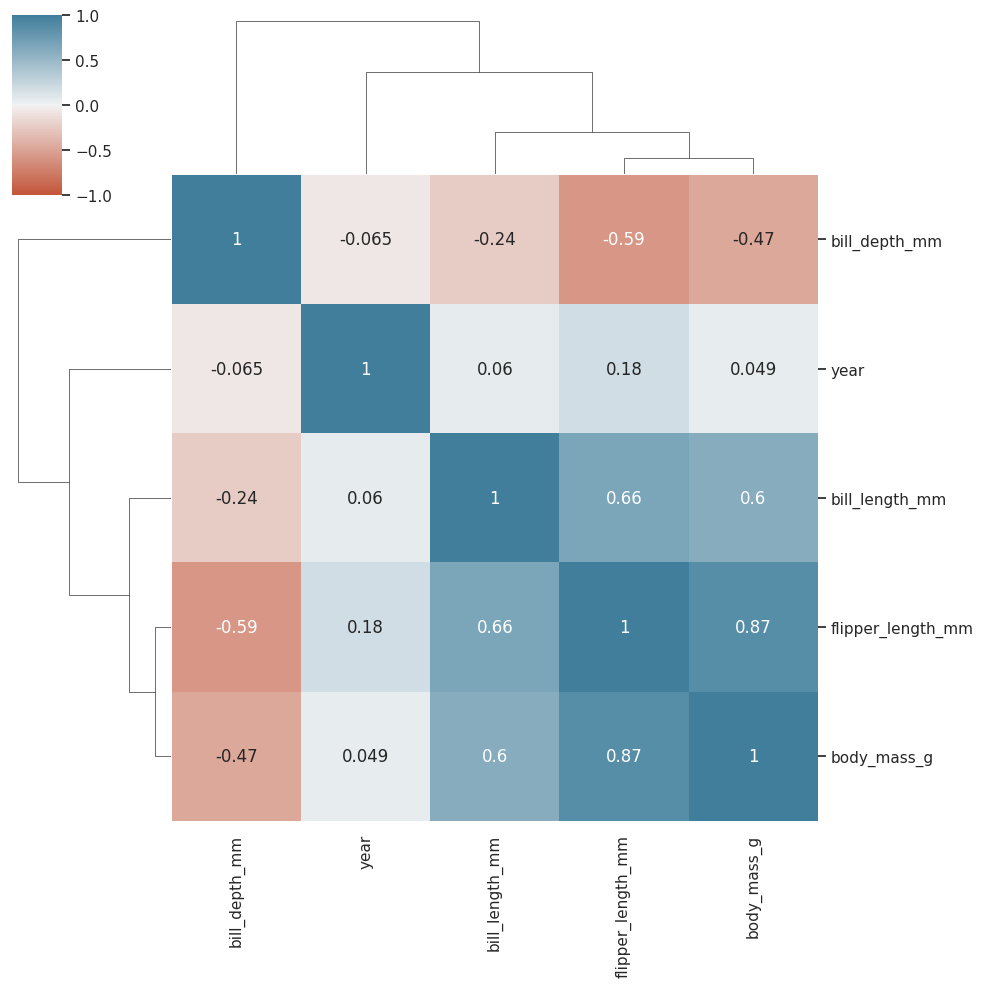

In [51]:
sns.clustermap(
    data=processed_palmerpenguins_df.corr(numeric_only=True),
    center=0,
    cmap=sns.diverging_palette(20, 230, as_cmap=True),
    vmin=-1,
    vmax=1,
    annot=True,
)

CATEGORICAL VARIABLES IN CORRECLATIONS

In [52]:
corr_palmerpenguins_df = pd.DataFrame(
    imputed_matrix,
    columns=encoded_df.columns,
    index=encoded_df.index
)

<Axes: >

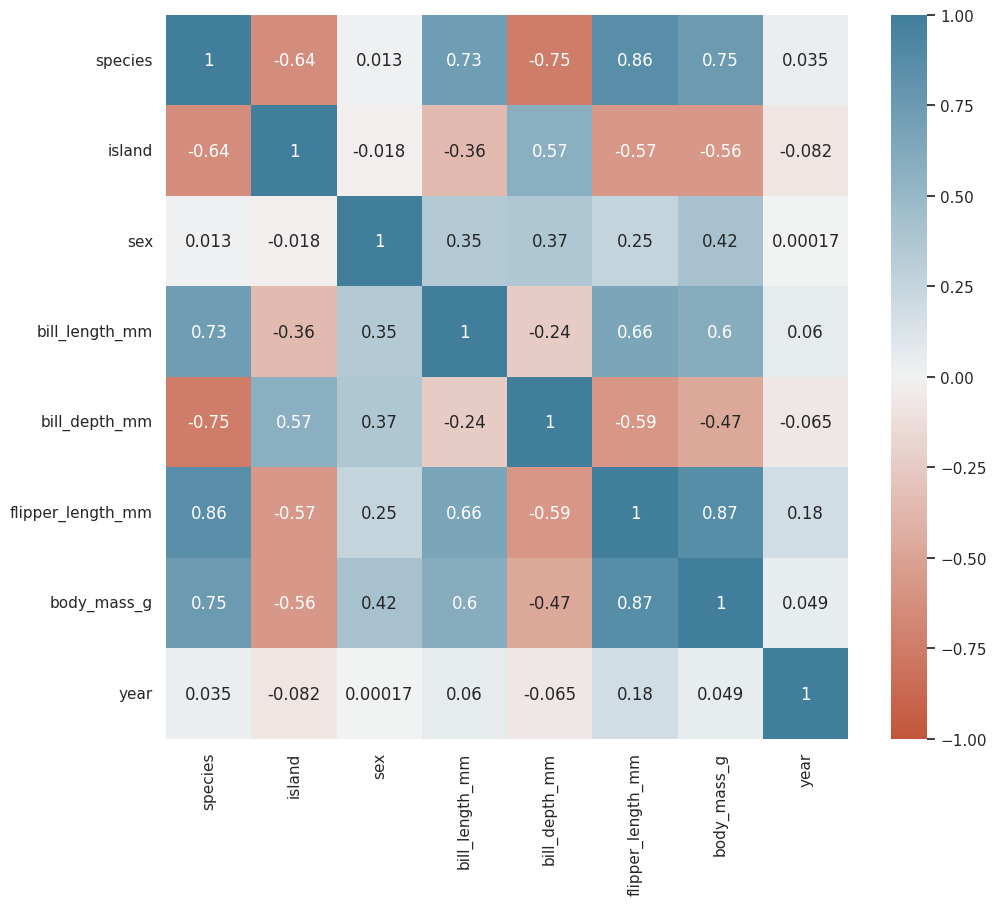

In [53]:
sns.heatmap(
    data=corr_palmerpenguins_df.corr(numeric_only=True),
    center=0,
    cmap=sns.diverging_palette(20, 230, as_cmap=True),
    vmin=-1,
    vmax=1,
    annot=True,
)

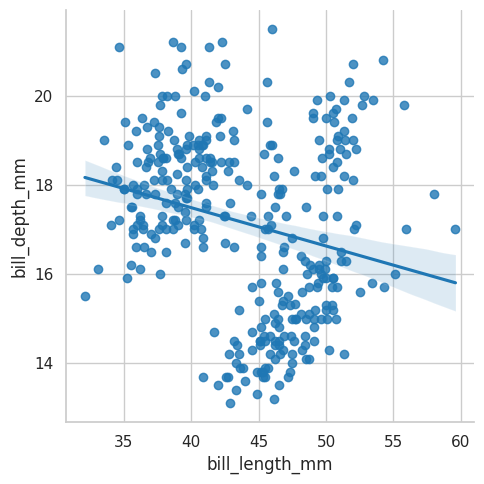

In [54]:
sns.lmplot(
    data=processed_palmerpenguins_df,
    y='bill_depth_mm',
    x='bill_length_mm',
)


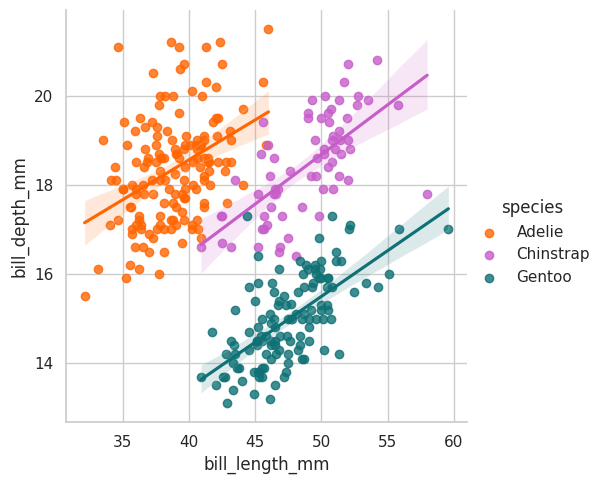

In [55]:
sns.lmplot(
    data=processed_palmerpenguins_df,
    x='bill_length_mm',
    y='bill_depth_mm',
    hue='species',
    palette=penguin_color,
)

# **The lineal Rregresion is not symetric**

In [56]:
x =  processed_palmerpenguins_df['bill_length_mm']
y =  processed_palmerpenguins_df['bill_depth_mm']

result_x_y = scipy.stats.linregress(x, y)
result_y_x = scipy.stats.linregress(y, x)

print(result_x_y)
print(result_y_x)

LinregressResult(slope=np.float64(-0.08590871801815672), intercept=np.float64(20.921982671862995), rvalue=np.float64(-0.23756408618281305), pvalue=np.float64(8.426735065325664e-06), stderr=np.float64(0.018994546101995892), intercept_stderr=np.float64(0.8405995015028369))
LinregressResult(slope=np.float64(-0.6569379260431658), intercept=np.float64(55.184208225550606), rvalue=np.float64(-0.23756408618281305), pvalue=np.float64(8.426735065325664e-06), stderr=np.float64(0.14524995844704863), intercept_stderr=np.float64(2.507266678539956))


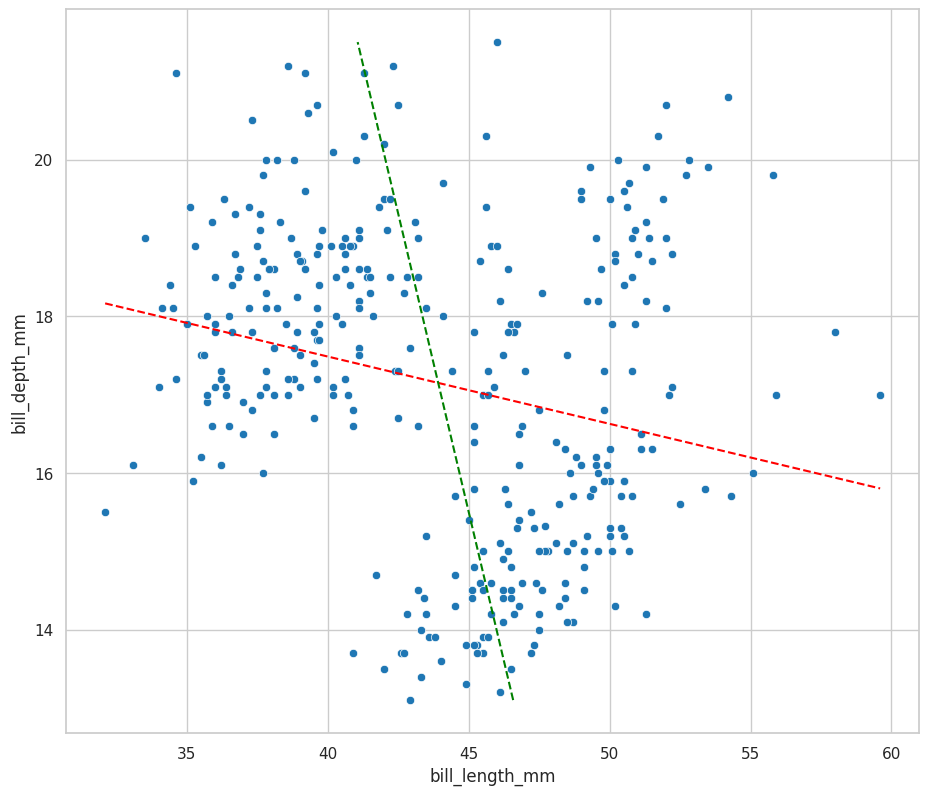

In [57]:
sns.scatterplot(
    x=x,
    y=y,
)

fx_1 = np.array([x.min(), x.max()])
fy_1 =  result_x_y.slope * fx_1 +result_x_y.intercept

fx_2 = np.array([y.min(), y.max()])
fy_2 =  result_y_x.slope * fx_2 +result_y_x.intercept

plt.plot(
    fx_1,
    fy_1,
    color='red',
    linestyle='--',
)

plt.plot(
    fy_2,
    fx_2,
    color='green',
    linestyle='--',
)

# **Multi Variable Analysis**

In [58]:
## Model 1

model_1 = (
    smf.ols(
        'body_mass_g ~ bill_length_mm',
        data=processed_palmerpenguins_df
    ).fit()
)

model_1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            body_mass_g   R-squared:                       0.356
Model:                            OLS   Adj. R-squared:                  0.354
Method:                 Least Squares   F-statistic:                     189.1
Date:                Thu, 08 Oct 2026   Prob (F-statistic):           1.47e-34
Time:                        05:24:58   Log-Likelihood:                -2712.2
No. Observations:                 344   AIC:                             5428.
Df Residuals:                     342   BIC:                             5436.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept        349.6153    282.333      1.238      0.216    -205.712     904.942
bill_length_mm    87.7316      6.380     13.752      0.000      75.183     100.280
==============================================================================
Omnibus:                        5.711   Durbin-Watson:                   0.863
Prob(Omnibus):                  0.058   Jarque-Bera (JB):                4.976
Skew:                          -0.219   Prob(JB):                       0.0831
Kurtosis:                       2.606   Cond. No.                         360.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [59]:
## Model 2

model_2 = (
    smf.ols(
        'body_mass_g ~ bill_length_mm + bill_depth_mm',
        data=processed_palmerpenguins_df
    ).fit()
)

model_2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            body_mass_g   R-squared:                       0.473
Model:                            OLS   Adj. R-squared:                  0.470
Method:                 Least Squares   F-statistic:                     153.1
Date:                Thu, 08 Oct 2026   Prob (F-statistic):           3.51e-48
Time:                        05:24:58   Log-Likelihood:                -2677.7
No. Observations:                 344   AIC:                             5361.
Df Residuals:                     341   BIC:                             5373.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept       3346.3152    428.813      7.804      0.000    2502.863    4189.767
bill_length_mm    75.4267      5.949     12.678      0.000      63.725      87.129
bill_depth_mm   -143.2321     16.452     -8.706      0.000    -175.592    -110.873
==============================================================================
Omnibus:                        2.378   Durbin-Watson:                   1.817
Prob(Omnibus):                  0.305   Jarque-Bera (JB):                1.921
Skew:                          -0.003   Prob(JB):                        0.383
Kurtosis:                       2.634   Cond. No.                         646.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [60]:
model_3 = (
    smf.ols(
        'body_mass_g ~ bill_length_mm + bill_depth_mm + flipper_length_mm',
        data=processed_palmerpenguins_df
    ).fit()
)

model_3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            body_mass_g   R-squared:                       0.763
Model:                            OLS   Adj. R-squared:                  0.761
Method:                 Least Squares   F-statistic:                     364.5
Date:                Thu, 08 Oct 2026   Prob (F-statistic):          7.50e-106
Time:                        05:24:58   Log-Likelihood:                -2540.4
No. Observations:                 344   AIC:                             5089.
Df Residuals:                     340   BIC:                             5104.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -6423.9352    559.409    -11.483      0.000   -7524.273   -5323.598
bill_length_mm        4.1407      5.312      0.779      0.436      -6.309      14.590
bill_depth_mm        20.0470     13.654      1.468      0.143      -6.809      46.903
flipper_length_mm    50.2713      2.467     20.376      0.000      45.419      55.124
==============================================================================
Omnibus:                        5.305   Durbin-Watson:                   2.041
Prob(Omnibus):                  0.070   Jarque-Bera (JB):                5.149
Skew:                           0.297   Prob(JB):                       0.0762
Kurtosis:                       3.081   Cond. No.                     5.47e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 5.47e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [61]:
model_4 = (
    smf.ols(
        'body_mass_g ~ bill_length_mm + bill_depth_mm + flipper_length_mm + C(sex)',
        data=processed_palmerpenguins_df
    ).fit()
)

model_4.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            body_mass_g   R-squared:                       0.817
Model:                            OLS   Adj. R-squared:                  0.815
Method:                 Least Squares   F-statistic:                     379.3
Date:                Thu, 08 Oct 2026   Prob (F-statistic):          9.69e-124
Time:                        05:24:58   Log-Likelihood:                -2495.5
No. Observations:                 344   AIC:                             5001.
Df Residuals:                     339   BIC:                             5020.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -2461.9166    629.878     -3.909      0.000   -3700.877   -1222.956
C(sex)[T.male]      516.1446     51.298     10.062      0.000     415.241     617.048
bill_length_mm       -1.6631      4.704     -0.354      0.724     -10.916       7.590
bill_depth_mm       -79.1117     15.527     -5.095      0.000    -109.654     -48.570
flipper_length_mm    39.0150      2.440     15.991      0.000      34.216      43.814
==============================================================================
Omnibus:                        0.181   Durbin-Watson:                   1.869
Prob(Omnibus):                  0.913   Jarque-Bera (JB):                0.271
Skew:                          -0.047   Prob(JB):                        0.873
Kurtosis:                       2.900   Cond. No.                     7.02e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.02e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [62]:
model_5 = (
    smf.ols(
        'body_mass_g ~ flipper_length_mm + C(sex)',
        data=processed_palmerpenguins_df
    ).fit()
)

model_5.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            body_mass_g   R-squared:                       0.803
Model:                            OLS   Adj. R-squared:                  0.802
Method:                 Least Squares   F-statistic:                     694.7
Date:                Thu, 08 Oct 2026   Prob (F-statistic):          5.41e-121
Time:                        05:24:58   Log-Likelihood:                -2508.6
No. Observations:                 344   AIC:                             5023.
Df Residuals:                     341   BIC:                             5035.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -5337.6013    280.648    -19.019      0.000   -5889.620   -4785.583
C(sex)[T.male]      341.3249     39.769      8.583      0.000     263.101     419.548
flipper_length_mm    46.6413      1.415     32.968      0.000      43.859      49.424
==============================================================================
Omnibus:                        0.002   Durbin-Watson:                   1.765
Prob(Omnibus):                  0.999   Jarque-Bera (JB):                0.035
Skew:                           0.006   Prob(JB):                        0.982
Kurtosis:                       2.952   Cond. No.                     2.94e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.94e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

# **Model Visualization**

In [63]:
models_results = pd.DataFrame(
    {
        'actual_value' : processed_palmerpenguins_df['body_mass_g'],
        'model_1': model_1.predict(),
        'model_2': model_2.predict(),
        'model_3': model_3.predict(),
        'model_4': model_4.predict(),
        'model_5': model_5.predict(),
        'species': processed_palmerpenguins_df['species'],
        'sex': processed_palmerpenguins_df['sex'],
    }
)

models_results


,actual_value,model_1,model_2,model_3,model_4,model_5,species,sex
0,3750.0,3779.921752,3617.059934,3211.955051,3571.521275,3445.801384,Adelie,male
1,3800.0,3815.014400,3833.432376,3438.906875,3352.631470,3337.683029,Adelie,female
2,3250.0,3885.199698,3807.834495,3906.689585,3654.968653,3757.454850,Adelie,female
3,3575.0,3762.375427,3667.861360,3513.587538,3333.993452,3393.652605,Adelie,female
4,3450.0,3569.365860,3350.096503,3817.301562,3480.080605,3664.172223,Adelie,female
...,...,...,...,...,...,...,...,...
339,4000.0,5245.039832,4719.131072,4610.210731,4471.114081,4658.475534,Chinstrap,male
340,3400.0,4165.940887,4034.876833,4273.843778,3914.840377,4083.944045,Chinstrap,female
341,3775.0,4701.103778,4480.656701,3848.664684,4061.794377,4005.497146,Chinstrap,male
342,4100.0,4806.381724,4456.583091,4724.283702,4659.763685,4798.399475,Chinstrap,male


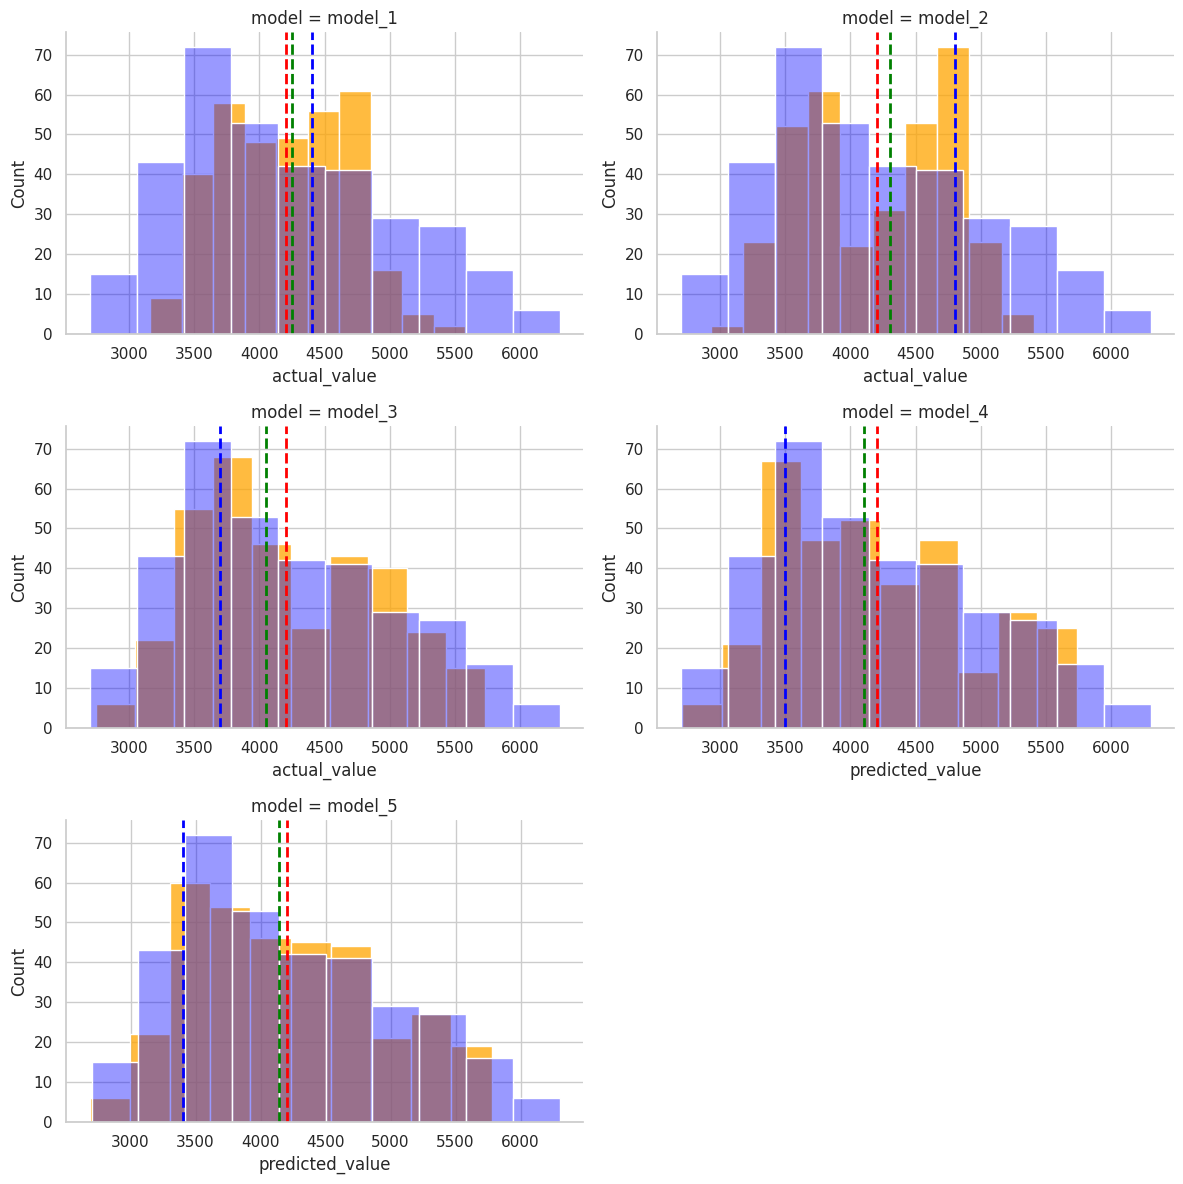

In [64]:
from functools import partial

# 1. Definimos los modelos a iterar (excluyendo el valor real)
model_cols = ['model_1', 'model_2', 'model_3', 'model_4', 'model_5']

# 2. Derretimos el DataFrame manteniendo solo los modelos en las filas,
# pero conservamos 'actual_value' como una columna de referencia en cada fila
df_melted = models_results.melt(
    id_vars=['actual_value'],
    value_vars=model_cols,
    var_name='model',
    value_name='predicted_value'
)

# 3. Creamos el displot mapeando cada modelo a una columna (panel) diferente
g = sns.displot(
    data=df_melted,
    x="predicted_value",
    col="model",
    kind="hist",
    bins=10,
    common_bins=False,
    facet_kws=dict(sharex=False, sharey=False),
    col_wrap=2,
    height=4,
    aspect=1.5,
    color="orange",       # Color para los modelos predictivos
    label="Modelo"
)

# 4. Inyectamos la distribución de 'actual_value' en cada panel de fondo
def draw_actual_distribution(data, **kwargs):
    # Dibujamos el histograma de la columna 'actual_value' compartida
    sns.histplot(data=data, x="actual_value", bins=10, color="blue", alpha=0.4, label="Actual")

# Aplicamos la distribución real, las medidas de tendencia y la leyenda
g.map_dataframe(draw_actual_distribution)


# Reemplaza la línea 39 por esto:
g.map_dataframe(partial(
    draw_central_tendency_measures,
    x_value="predicted_value",
    include_mode=True,
    round_decimals=-2
    ))


plt.show()


**ECD**

<Axes: ylabel='Proportion'>

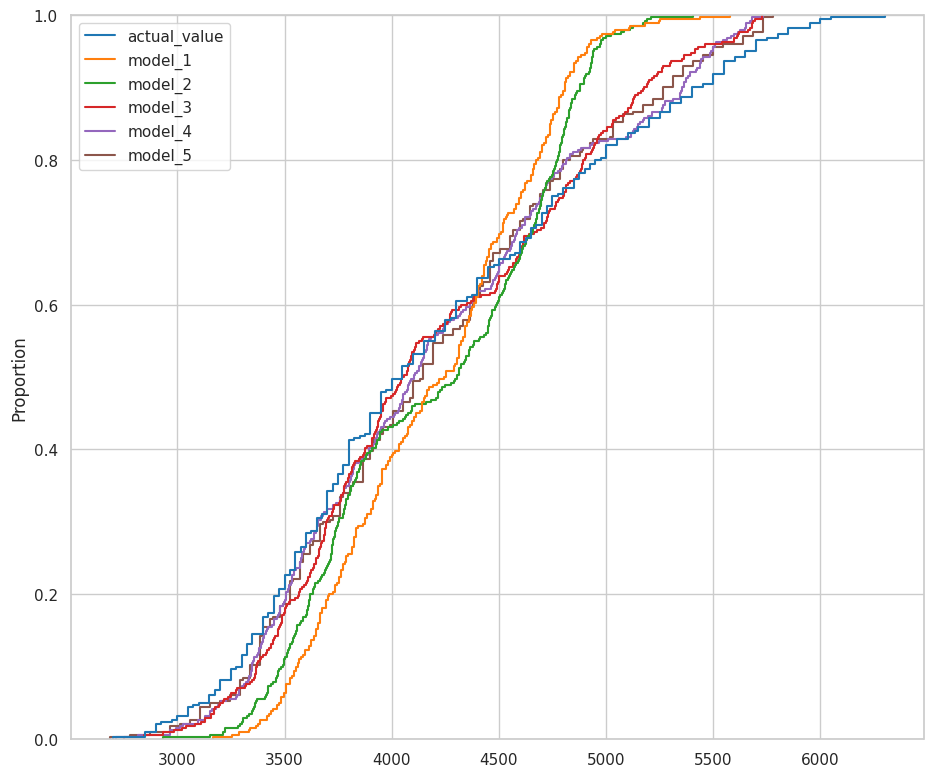

In [65]:
sns.ecdfplot(
    data=models_results,
)

# **PDF'S**

<Axes: ylabel='Density'>

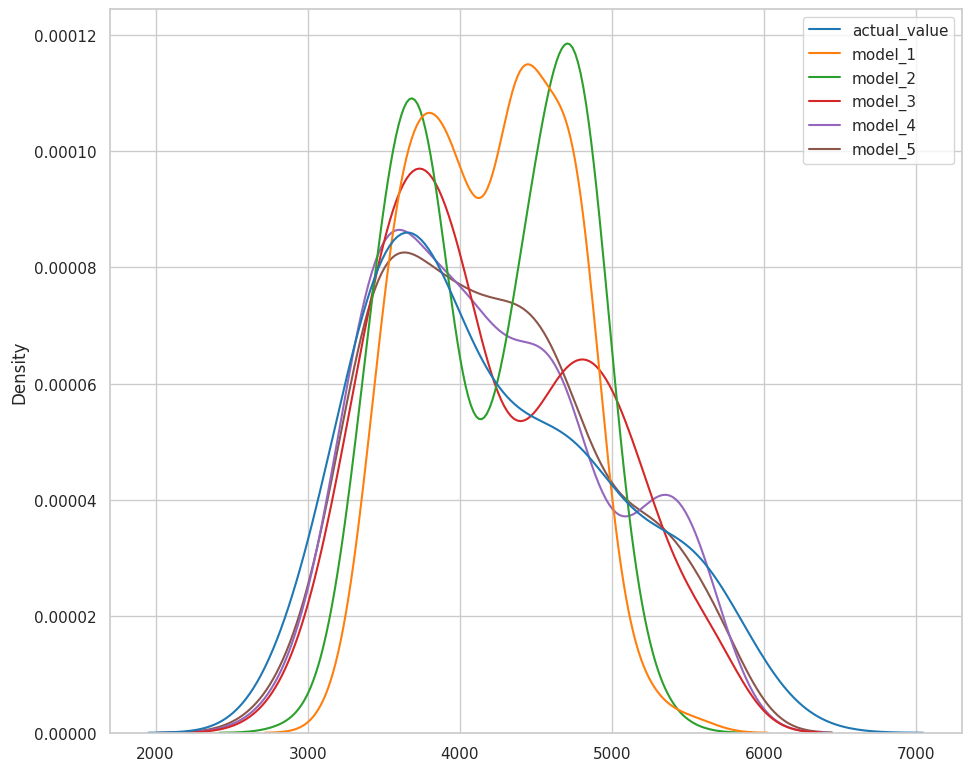

In [66]:
sns.kdeplot(
    data=models_results
)

# **Logisictic Regression**

In [67]:
smf.logit(
    formula = 'sex ~ flipper_length_mm + bill_length_mm + bill_depth_mm + island',
    data = corr_palmerpenguins_df
).fit().summary()


Optimization terminated successfully.
         Current function value: 0.373599
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                    sex   No. Observations:                  344
Model:                          Logit   Df Residuals:                      339
Method:                           MLE   Df Model:                            4
Date:                Thu, 08 Oct 2026   Pseudo R-squ.:                  0.4610
Time:                        05:25:00   Log-Likelihood:                -128.52
converged:                       True   LL-Null:                       -238.44
Covariance Type:            nonrobust   LLR p-value:                 2.028e-46
=====================================================================================
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept           -60.6540      6.613     -9.173      0.000     -73.614     -47.694
flipper_length_mm     0.1525      0.022      6.851      0.000       0.109       0.196
bill_length_mm        0.0979      0.040      2.444      0.015       0.019       0.176
bill_depth_mm         1.5288      0.171      8.962      0.000       1.194       1.863
island               -0.5733      0.287     -1.997      0.046      -1.136      -0.011
=====================================================================================
"""

In [68]:
smf.logit(
    formula = 'sex ~ flipper_length_mm + bill_length_mm + bill_depth_mm + C(island)',
    data = processed_palmerpenguins_df.assign(
        sex=lambda d: d['sex'].astype(str)
        .replace({'male': 1, 'female': 0})
        .astype(int))
).fit().summary()


Optimization terminated successfully.
         Current function value: 0.365098
         Iterations 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                    sex   No. Observations:                  344
Model:                          Logit   Df Residuals:                      338
Method:                           MLE   Df Model:                            5
Date:                Thu, 08 Oct 2026   Pseudo R-squ.:                  0.4732
Time:                        05:25:00   Log-Likelihood:                -125.59
converged:                       True   LL-Null:                       -238.42
Covariance Type:            nonrobust   LLR p-value:                 9.146e-47
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                -60.5398      6.738     -8.985      0.000     -73.746     -47.334
C(island)[T.Dream]        -1.5359      0.489     -3.143      0.002      -2.494      -0.578
C(island)[T.Torgersen]    -1.0875      0.581     -1.873      0.061      -2.226       0.051
flipper_length_mm          0.1358      0.023      5.866      0.000       0.090       0.181
bill_length_mm             0.1431      0.044      3.233      0.001       0.056       0.230
bill_depth_mm              1.6210      0.180      9.015      0.000       1.269       1.973
==========================================================================================
"""

In [69]:
processed_palmerpenguins_df = (
    processed_palmerpenguins_df
    .assign(
        is_adelie=lambda d: d['species'].astype(str)
        .replace({'Adelie': 1, 'Gentoo': 0, 'Chinstrap':0})
        .astype(int)
    )
)

In [70]:
model_adeli = smf.logit(
    formula = 'is_adelie ~ flipper_length_mm + C(sex)',
    data = processed_palmerpenguins_df
).fit()

model_adeli.summary()

Optimization terminated successfully.
         Current function value: 0.347769
         Iterations 8


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              is_adelie   No. Observations:                  344
Model:                          Logit   Df Residuals:                      341
Method:                           MLE   Df Model:                            2
Date:                Thu, 08 Oct 2026   Pseudo R-squ.:                  0.4933
Time:                        05:25:00   Log-Likelihood:                -119.63
converged:                       True   LL-Null:                       -236.11
Covariance Type:            nonrobust   LLR p-value:                 2.593e-51
=====================================================================================
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            41.1856      4.657      8.845      0.000      32.059      50.312
C(sex)[T.male]        1.2600      0.355      3.553      0.000       0.565       1.955
flipper_length_mm    -0.2127      0.024     -8.781      0.000      -0.260      -0.165
=====================================================================================
"""

In [71]:
is_adeli_df = pd.DataFrame(
    {
        'actual_value':processed_palmerpenguins_df['is_adelie'],
        'model_adeli': model_adeli.predict().round(),
    }
)

is_adeli_df


,actual_value,model_adeli
0,1,1.0
1,1,1.0
2,1,0.0
3,1,1.0
4,1,1.0
...,...,...
339,0,0.0
340,0,0.0
341,0,1.0
342,0,0.0


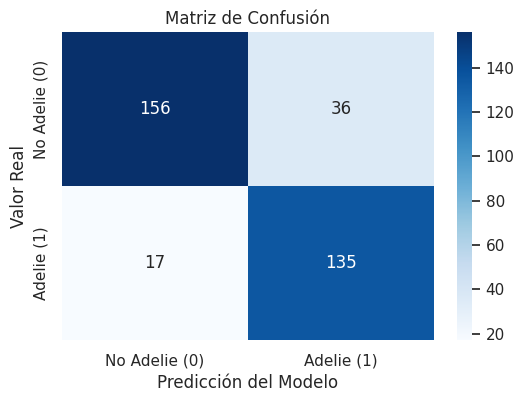

In [72]:
from sklearn.metrics import confusion_matrix

# Calcular la matriz de confusión
cm = confusion_matrix(is_adeli_df['actual_value'], is_adeli_df['model_adeli'])

# Graficar
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Adelie (0)', 'Adelie (1)'],
            yticklabels=['No Adelie (0)', 'Adelie (1)'])

plt.ylabel('Valor Real')
plt.xlabel('Predicción del Modelo')
plt.title('Matriz de Confusión')
plt.show()

<Axes: xlabel='actual_value', ylabel='count'>

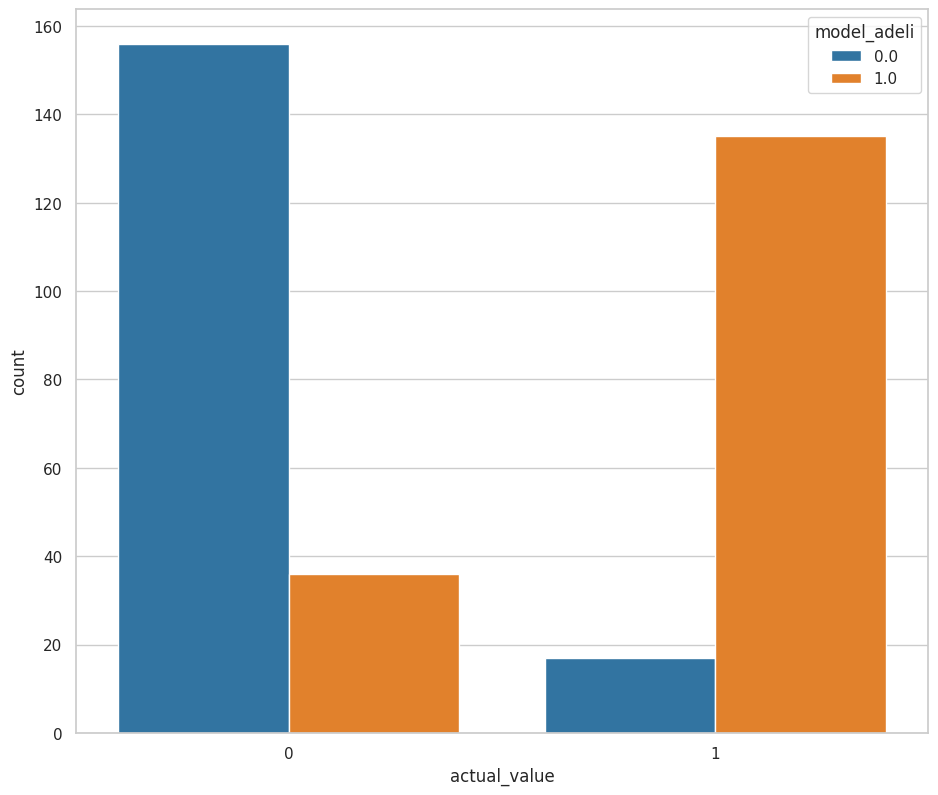

In [73]:
sns.countplot(
    data=is_adeli_df,
    x='actual_value',
    hue='model_adeli'

)

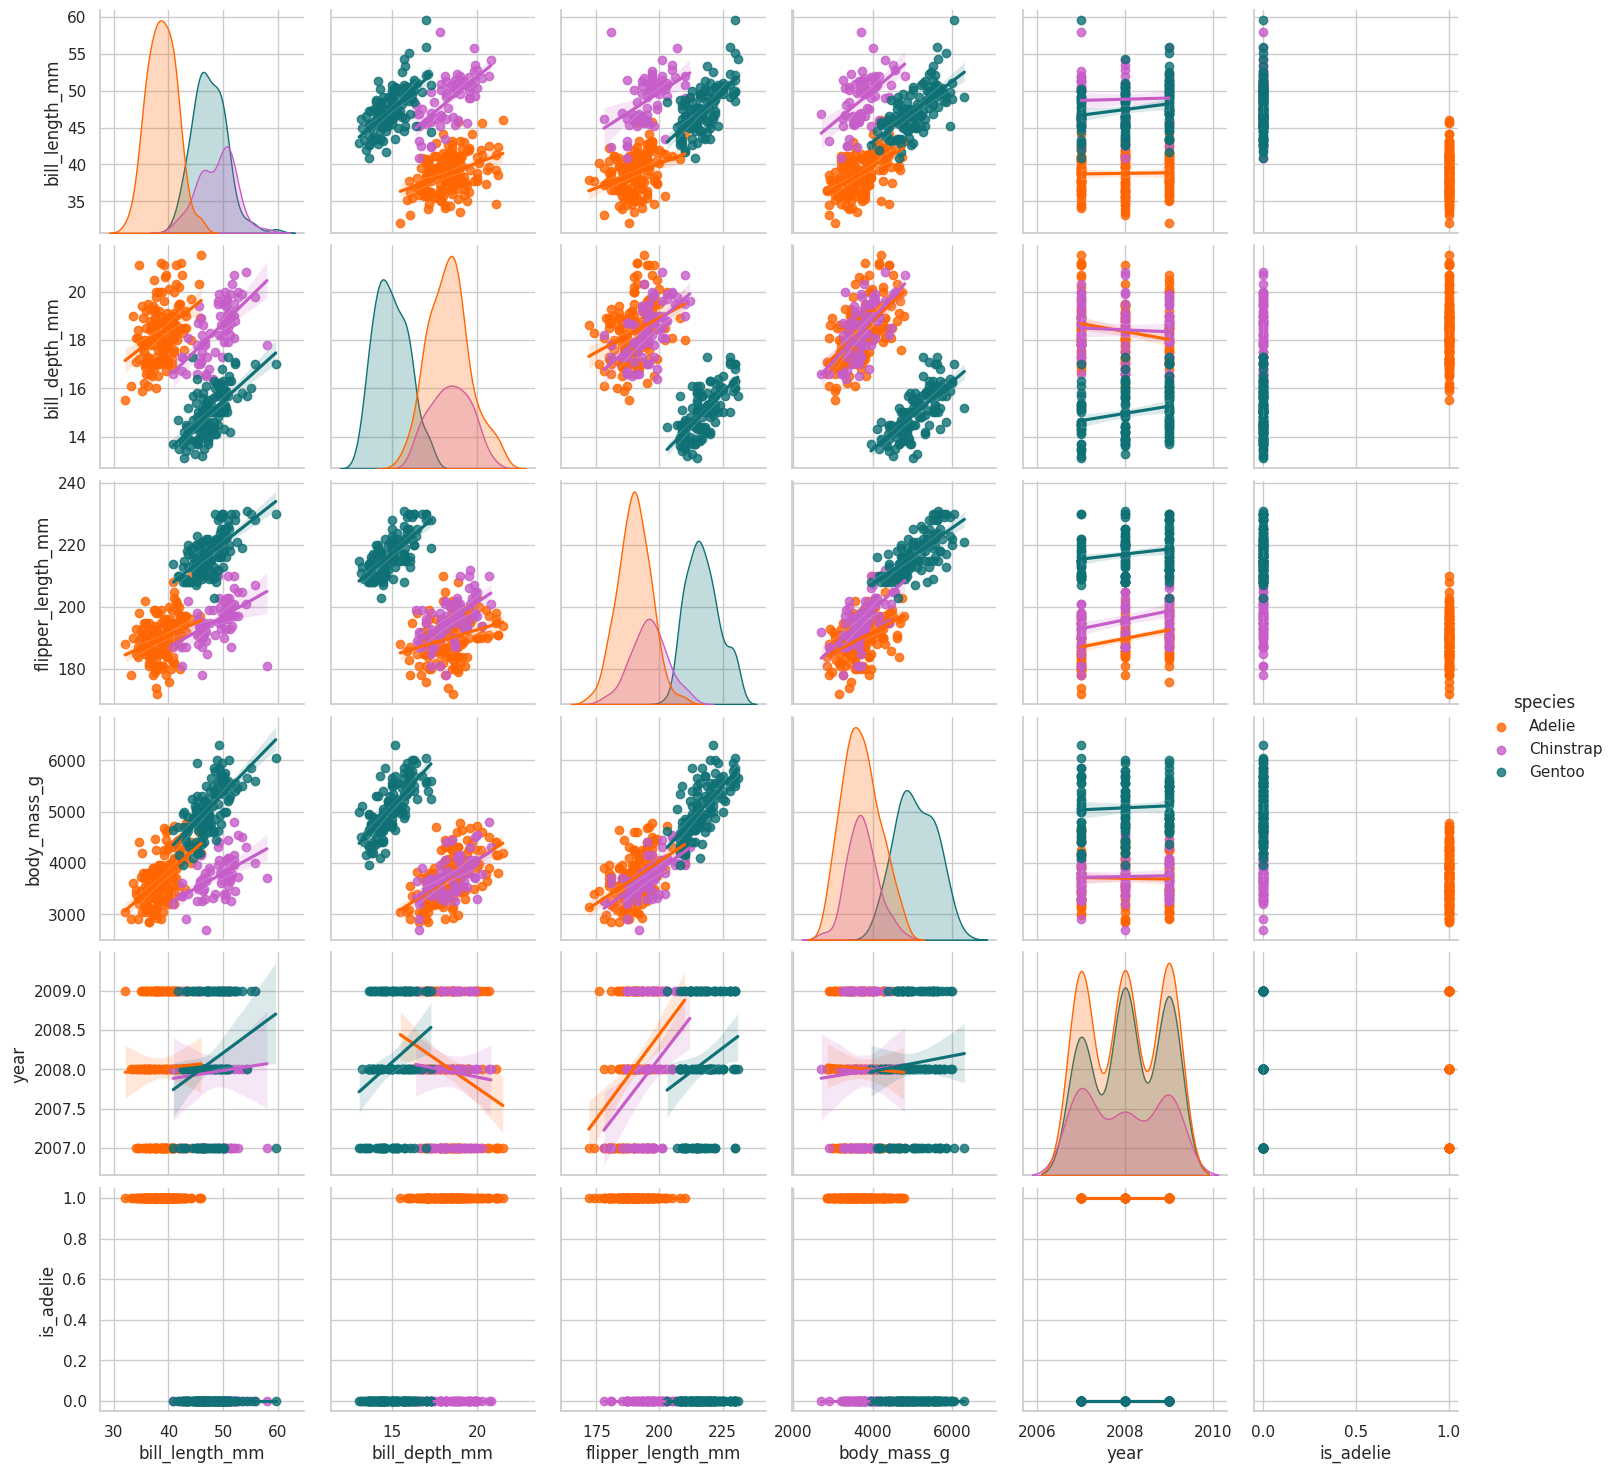

In [74]:
sns.pairplot(
    data=processed_palmerpenguins_df,
    hue='species',
    palette=penguin_color,
    kind='reg',  # Añade líneas de regresión lineal
)

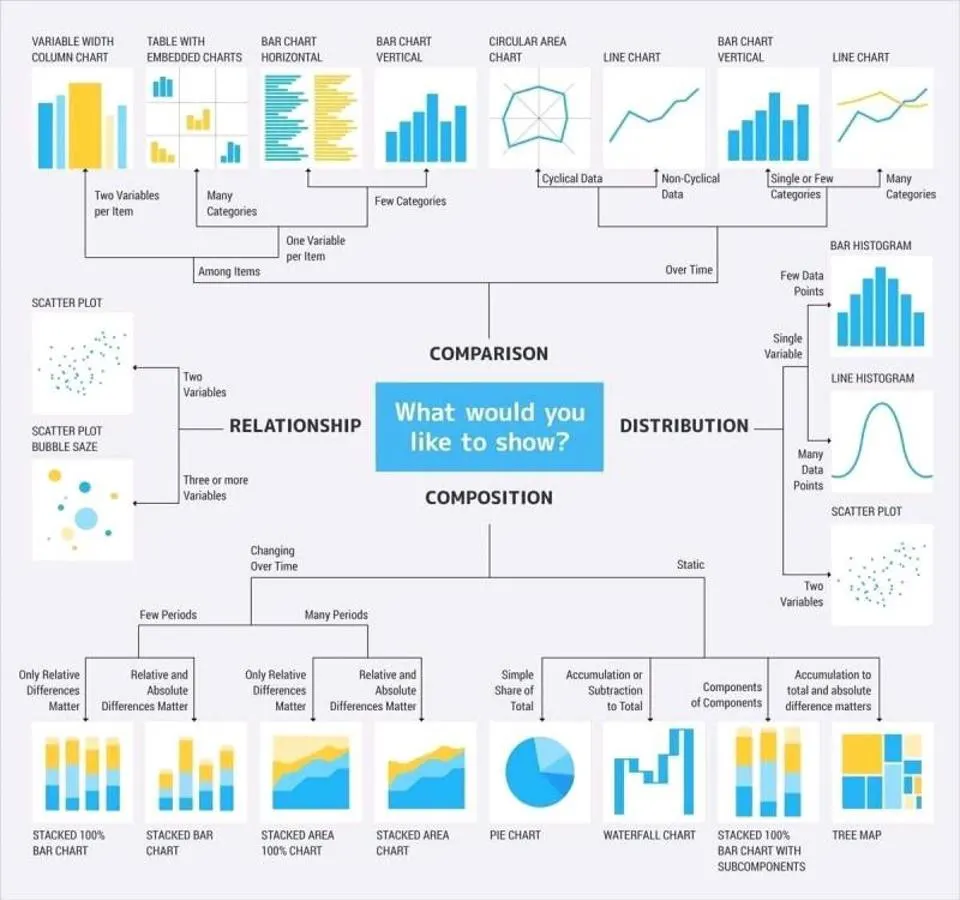

In [75]:
!pip install -U ydata-profiling

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 73.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 103.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 3.5 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 3.0.6
    Uninstalling pandas-3.0.6:
      Successfully uninstalled pandas-3.0.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pyjanitor 0.32.36 requires pandas>=

In [76]:
#from ydata_profiling import ProfileReport
#import palmerpenguins

# 1. Cargar el dataset original
#df = palmerpenguins.load_penguins()

# 2. SOLUCIÓN RADICAL: Activar el modo minimalista estricto
# Esto deshabilita por completo la función chi_square que causa el fallo
#profile = ProfileReport(
#    df,
#    title="Reporte de Pingüinos",
#    minimal=True
#)

# 3. Mostrar el reporte interactivo en Colab
#profile.to_notebook_iframe()


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.1/15.1 MB 62.2 MB/s eta 0:00:00


                                             |          | [  0%]   00:00 -> (? left)


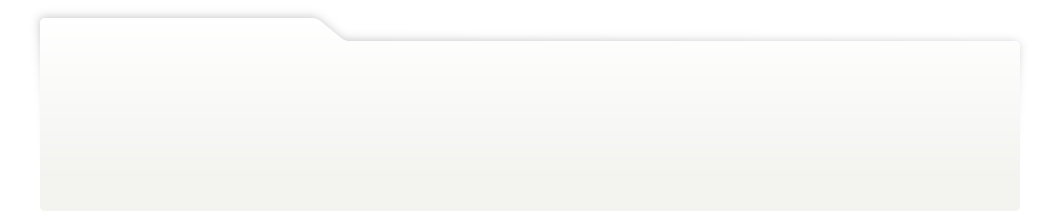
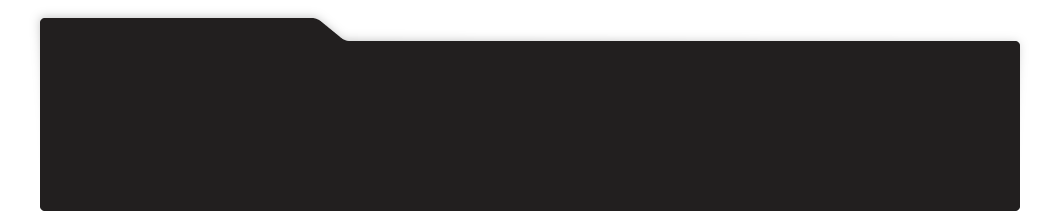
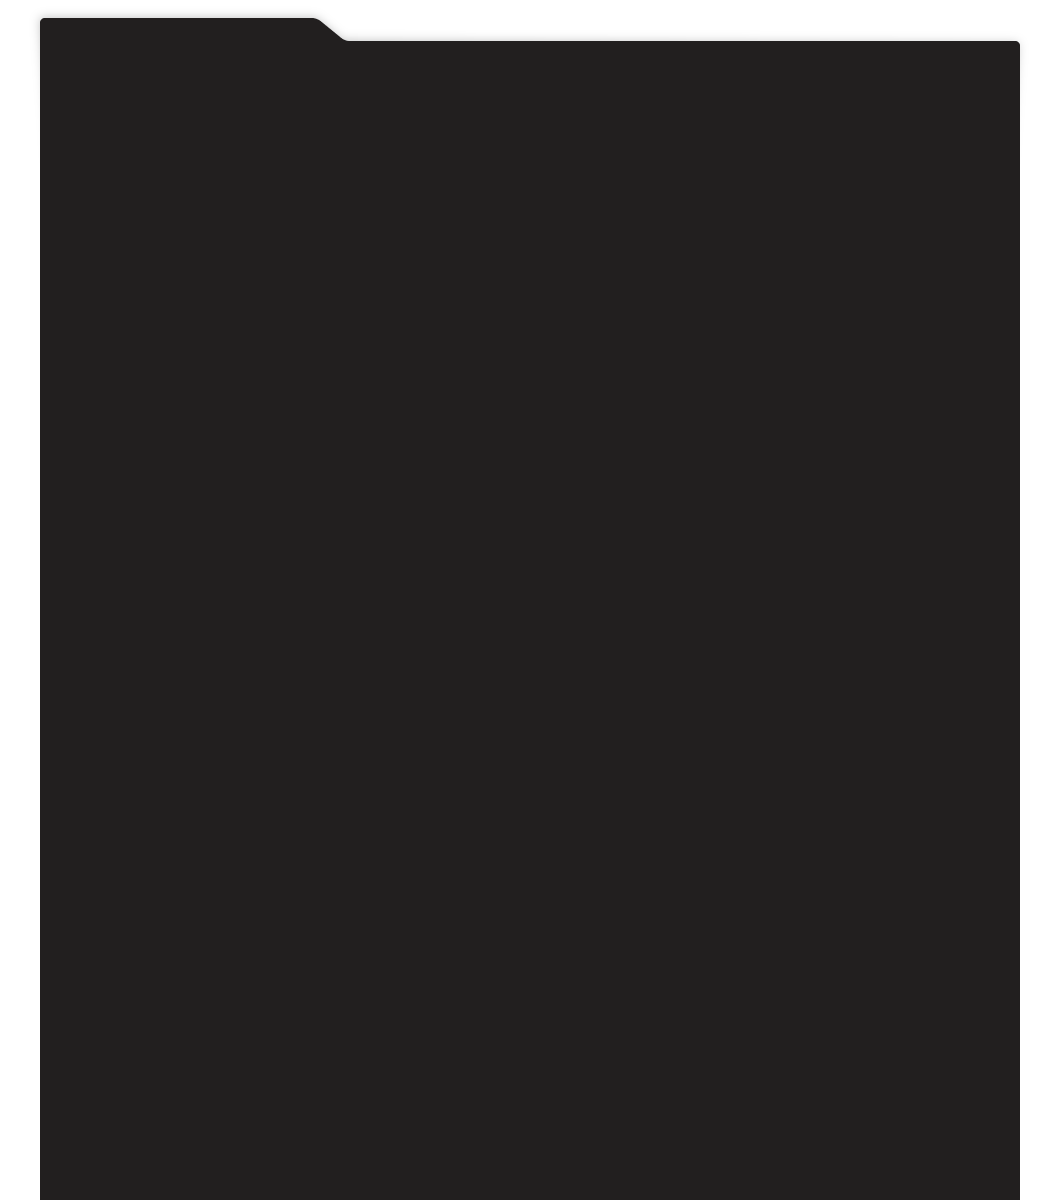
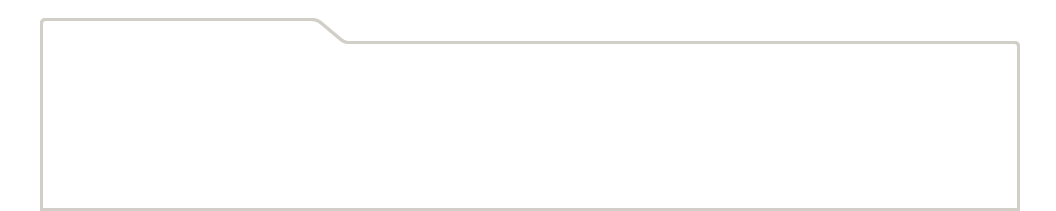
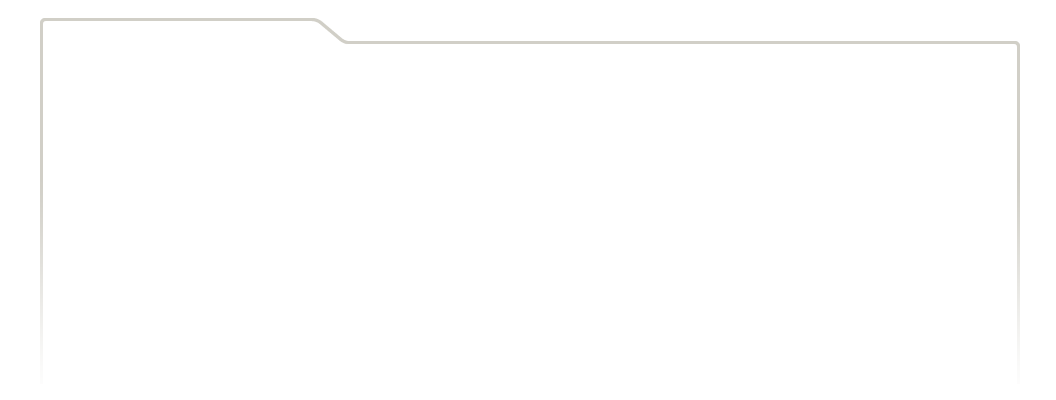
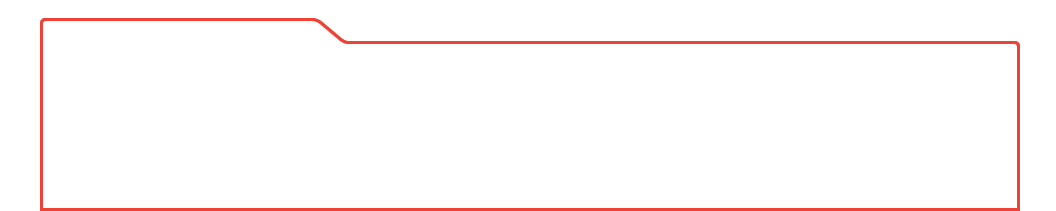
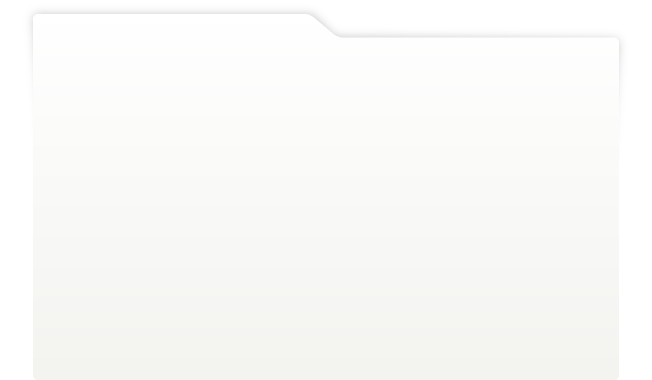
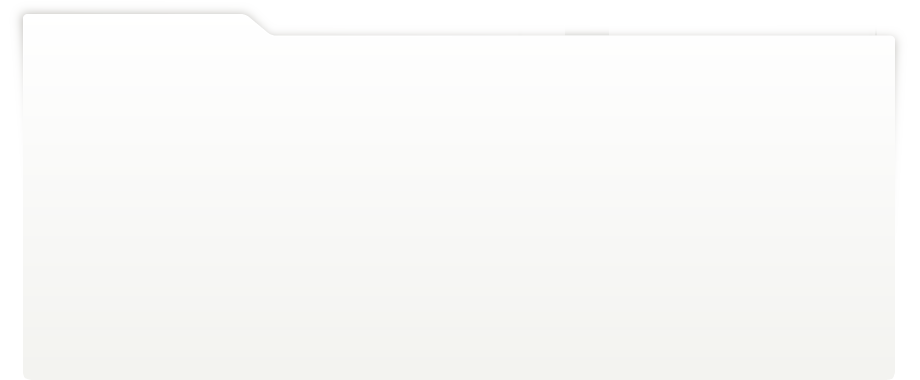
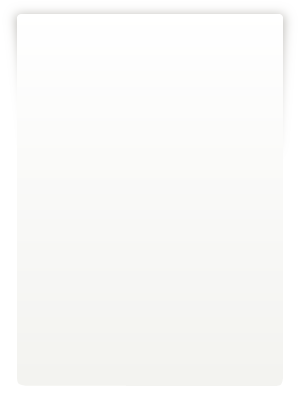
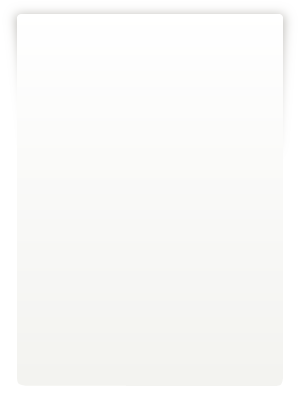
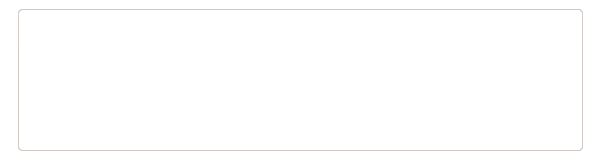
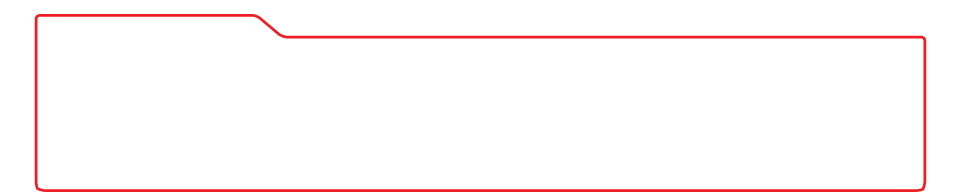
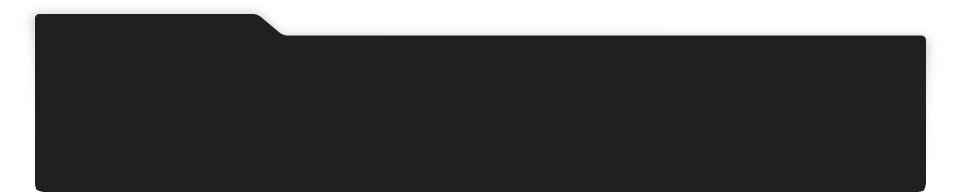
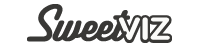
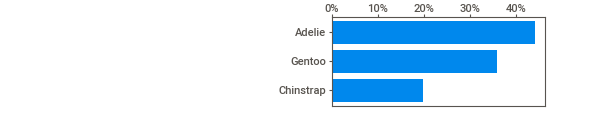
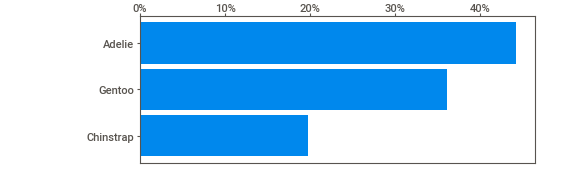
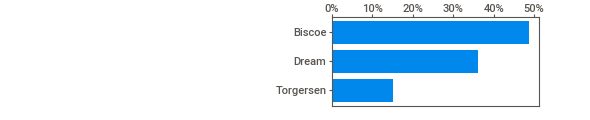
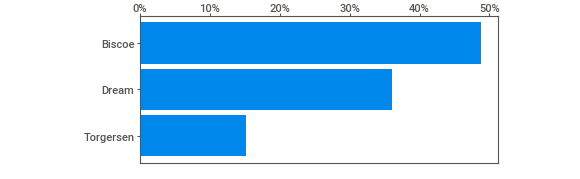
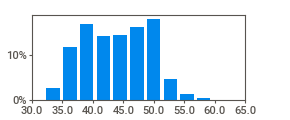
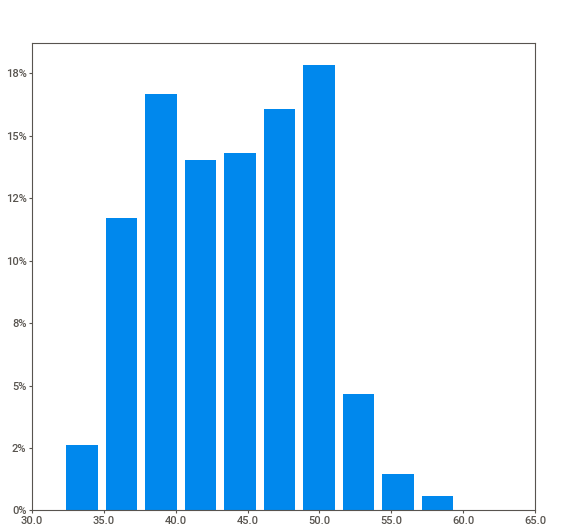
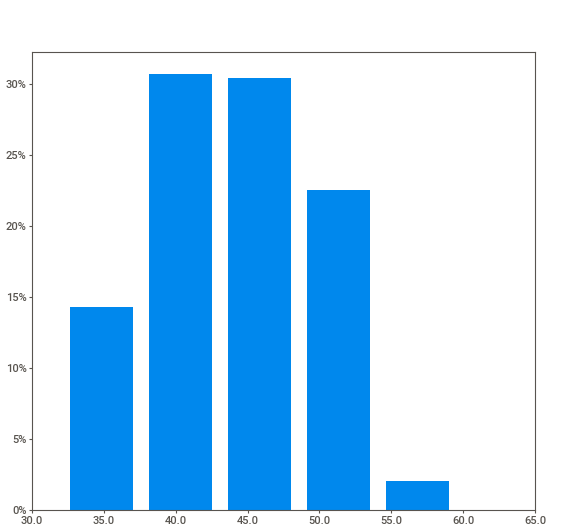
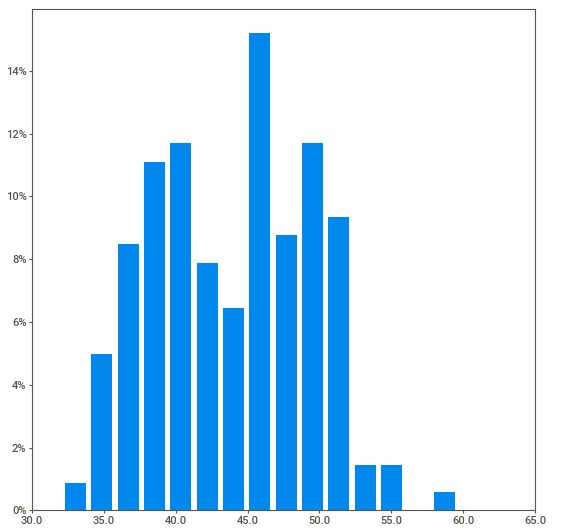
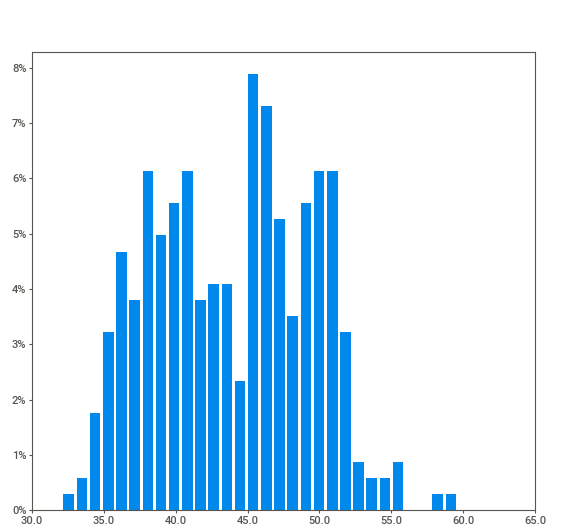
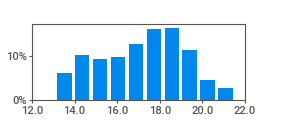
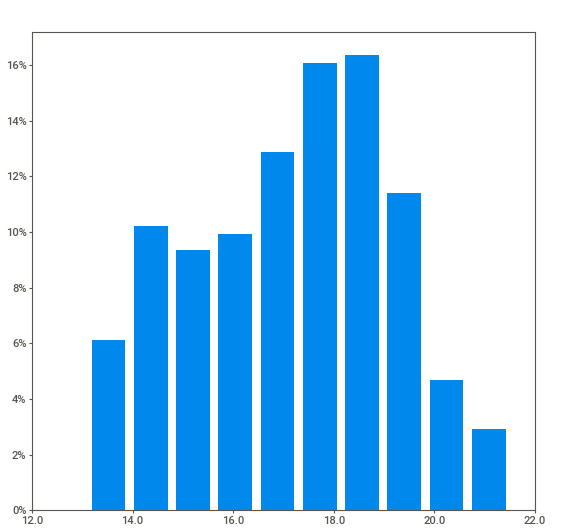
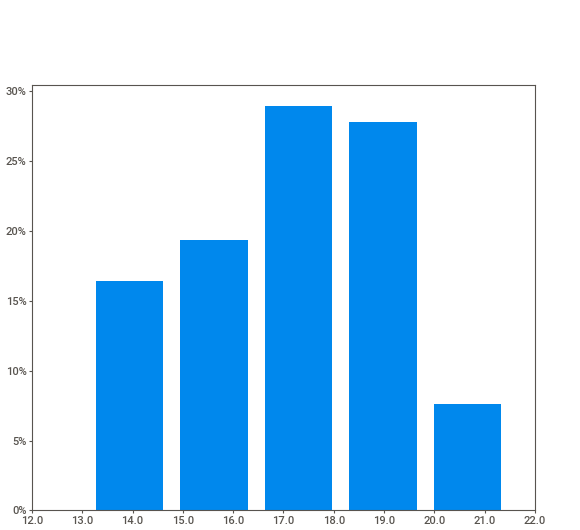
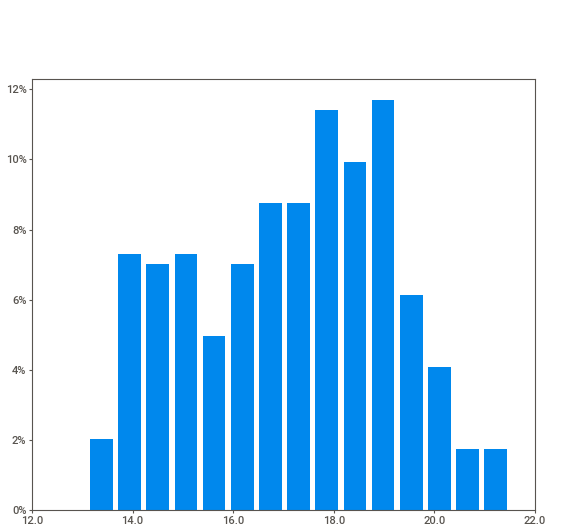
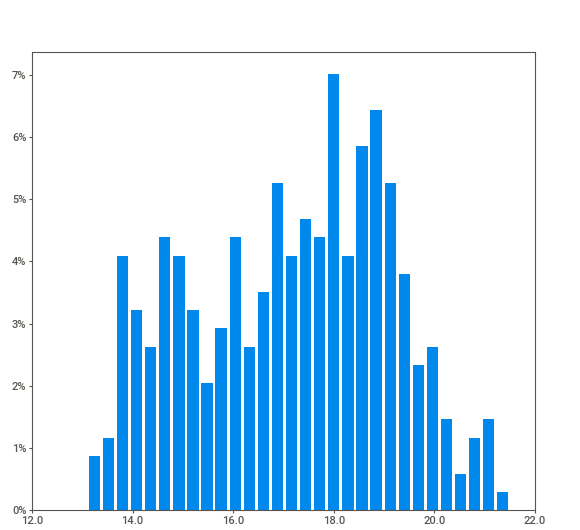
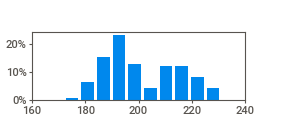
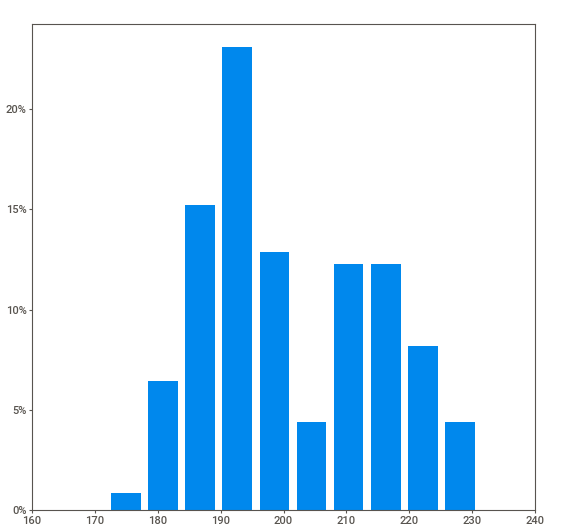
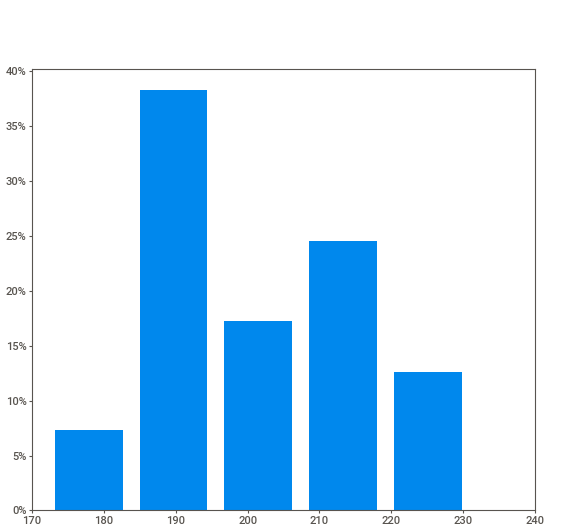
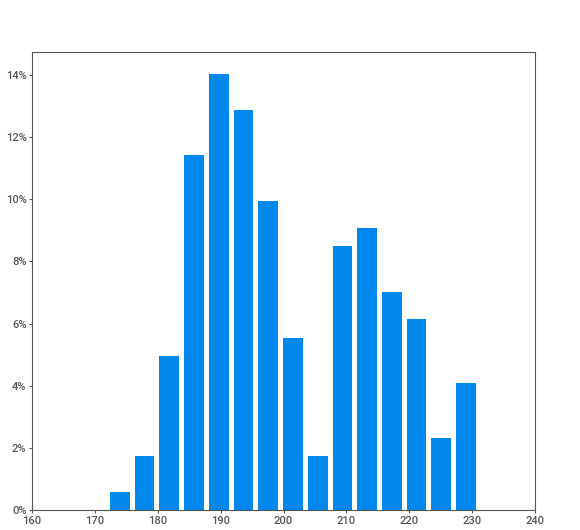
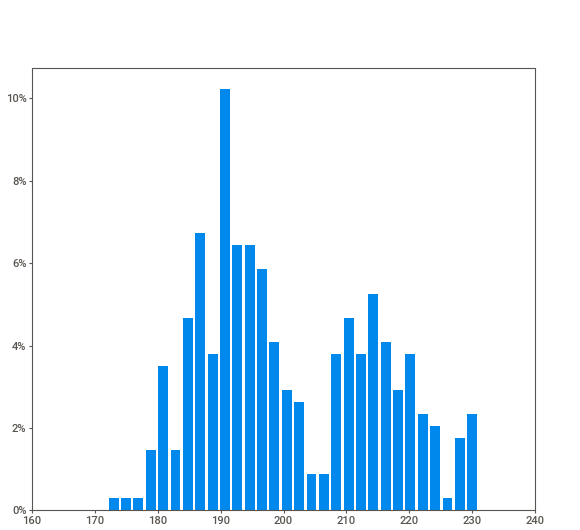
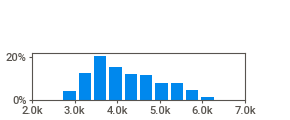
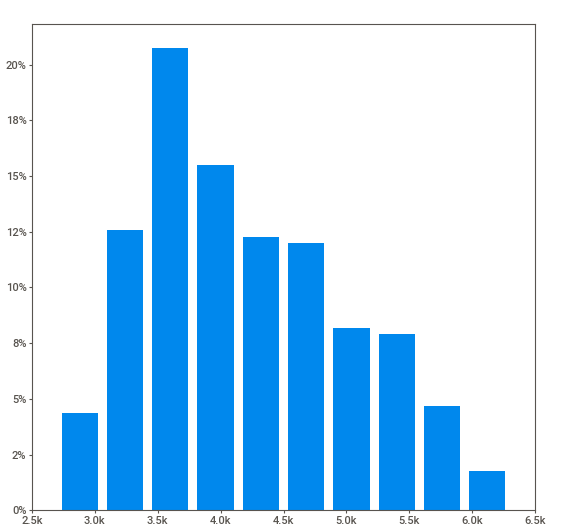
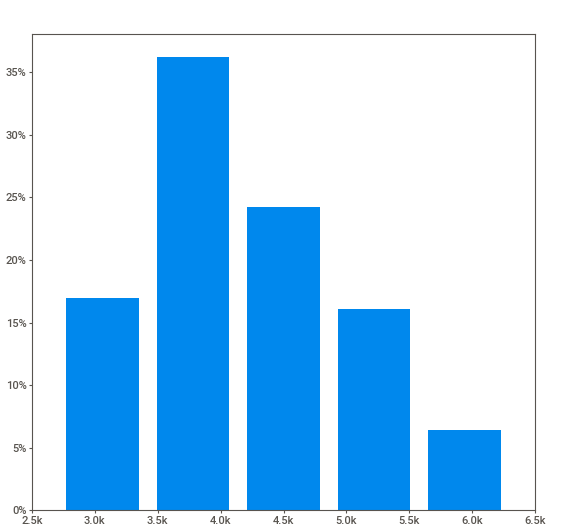
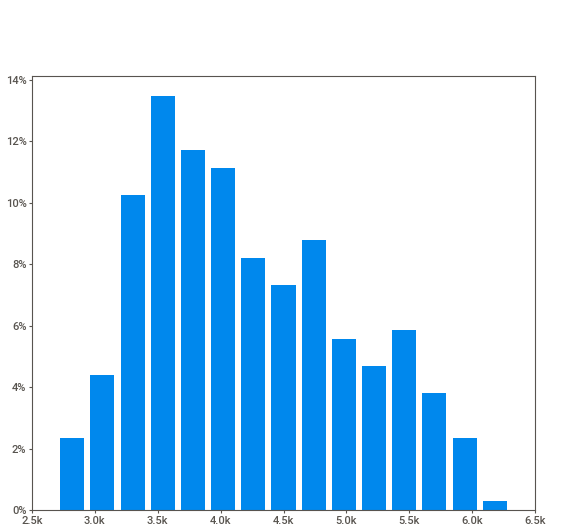
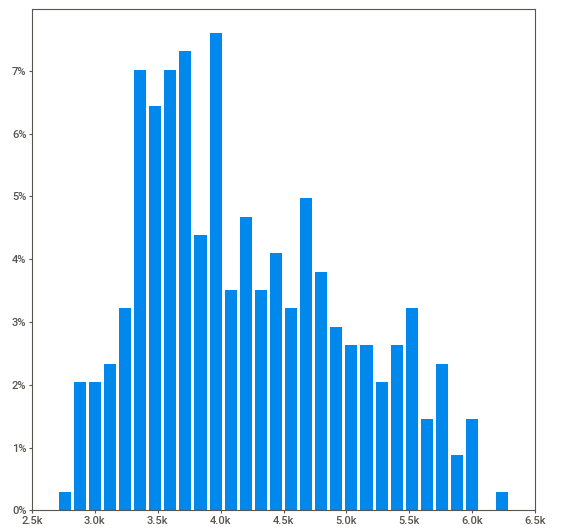
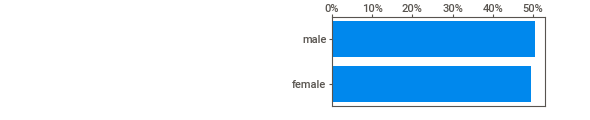
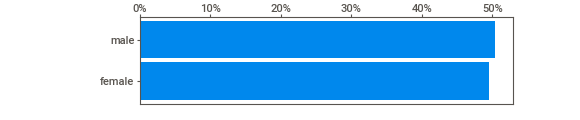
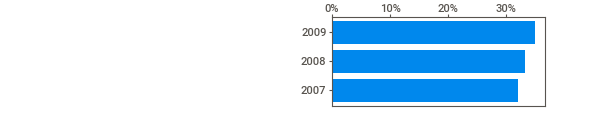
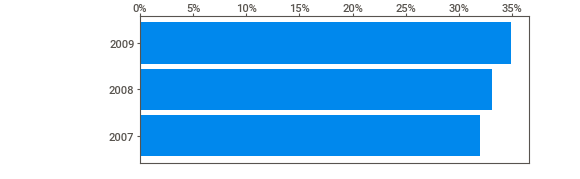
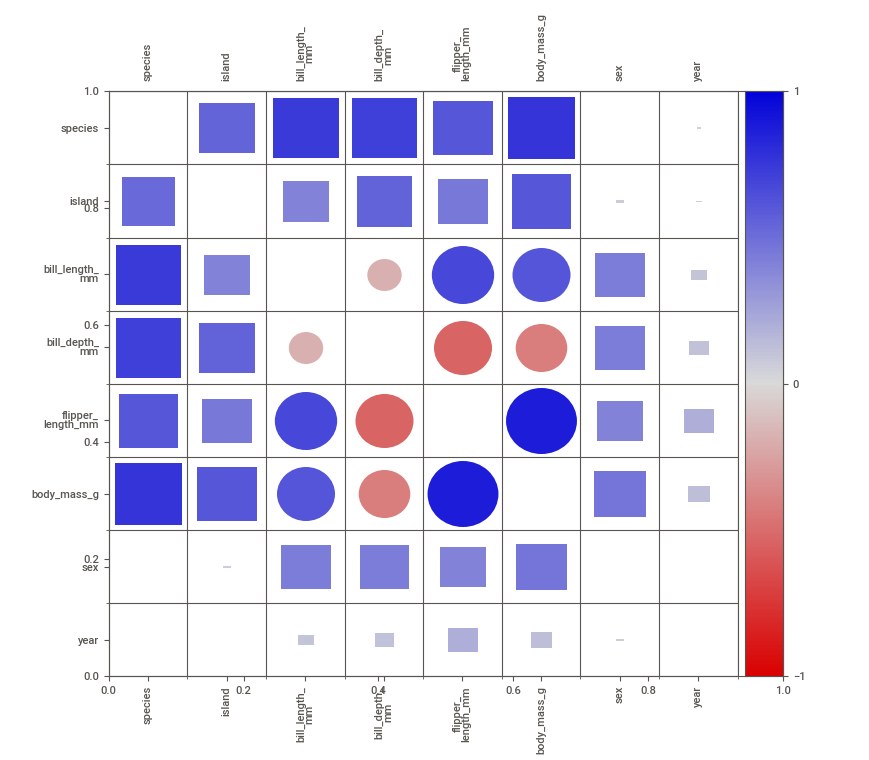
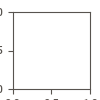

In [77]:
# 1. Instalar Sweetviz (Sin conflictos con Python 3.13)
!pip install sweetviz

import sweetviz as sv
import palmerpenguins

# 2. Cargar los datos
df = palmerpenguins.load_penguins()

# 3. Generar el reporte automatizado
reporte = sv.analyze(df)

# 4. Mostrarlo directamente en la pantalla de Colab
reporte.show_notebook()
